# Pairwise Solver Comparison — Reproducible Conference-Paper Analysis

This notebook documents **pairwise Max-Cut solution-quality comparisons** between the CPU-based Digital Annealer configuration **DAv3c**, the hardware-based **DAv2 / DAv3** systems, and the selected **MQLib heuristic** baseline.

## Reading guide

1. **Setup and data** — load enriched benchmark results and describe the categories.
2. **DAv3c versus heuristics** — win/tie/loss, cut-ratio counts, and Wilcoxon analysis.
3. **DAv2 versus DAv3** — hardware-to-hardware comparison.
4. **DAv3c versus DAv3** — direct CPU–hardware comparison.
5. **DAv3c versus DAv2** — comparison on DAv2-eligible instances.
6. **Weight representation** — integer vs. non-integer edge weights, including a matched-instance comparison.
7. **Sensitivity and supplemental analyses** — statistical normalization, XLarge, and small-instance checks.

### Interpretation conventions

- **Win / tie / loss** is always defined *from the perspective of the first solver* in the named comparison, using the repository's `utils.compare_scores` implementation.
- A **tie** means identical (or comparator-equivalent) reported cut scores under that utility; this is **not** a proof of optimality.
- **Category** is constructed as `size_cat + "_" + density_cat`.
- **Cut ratio** compares the cut value of the named solver to its specified baseline. Values above one favor the numerator **when the denominator is positive**; edge cases and tie handling follow `utils.compute_cut_ratio_counts`.
- **Wilcoxon tests** compare paired cut values. The category-specific tables include Holm-adjusted p-values where the utility provides them. Statistical significance does not quantify the magnitude of a performance difference.
- **Population matters:** the main pairwise comparisons may cover different eligible instances. DAv2-based comparisons exclude XLarge instances; later matched analyses explicitly check common instance IDs.

## 1. Environment and project modules

The notebook uses common configuration and analysis helpers from `src/maxcut`. The path below is **relative to the notebook's working directory** (normally the repository's `notebooks/` folder). Autoreload is useful during development; figure creation is handled by the plotting helpers.

In [1]:
# Purpose: Initialize shared dependencies, repository utilities, plot styling, and the output directory.
from pathlib import Path
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

# Project imports
sys.path.append(str(Path("../src/maxcut").resolve()))

%load_ext autoreload
%autoreload 2

import config as cfg
import plotting
import utils

plotting.set_plot_style()
cfg.FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {cfg.FIGURE_DIR}")

Figures will be saved to: /Users/sargun/Desktop/DAMB-DAv3c/results/figures


## 2. Load the enriched benchmark results

`baseline_enriched.csv` is the input table for this analysis. It must contain the solver cut values, chosen MQLib heuristic reference, graph instance identifiers (`name`), size/density group labels, and the `int_only` edge-weight flag. The analysis operates on these recorded cut values; it does not rerun any solver.

In [2]:
# Purpose: Read the precomputed benchmark table and inspect its dimensions and available fields.
BASELINE_ENRICHED = cfg.PROCESSED_DIR / "baseline_enriched.csv"

df_baseline = pd.read_csv(BASELINE_ENRICHED)

print("Shape:", df_baseline.shape)
print("Columns:")
print(df_baseline.columns.tolist())

df_baseline.head()

Shape: (3400, 24)
Columns:
['name', 'nodes', 'edges', 'density', 'limit', 'has_leafs', 'int_only', 'size_cat', 'density_cat', 'heuristics_name', 'DAv2', 'DAv2_runtime', 'DAv3', 'DAv3_runtime', 'DAv3c', 'DAv3c_runtime', 'BURER2002', 'BURER2002_runtime', 'MERZ1999GLS', 'MERZ1999GLS_runtime', 'PAL2004bMTS2', 'PAL2004bMTS2_runtime', 'heuristic', 'heuristic_runtime']


,name,nodes,edges,density,limit,has_leafs,int_only,size_cat,density_cat,heuristics_name,...,DAv3c,DAv3c_runtime,BURER2002,BURER2002_runtime,MERZ1999GLS,MERZ1999GLS_runtime,PAL2004bMTS2,PAL2004bMTS2_runtime,heuristic,heuristic_runtime
0,G55,4969,12498,0.001013,13.945,True,True,large,sparse,BURER2002,...,10200.0,13.121273,10249.0,13.960023,10169.0,13.945797,10171.0,14.007015,10249.0,13.960023
1,G56,4969,12498,0.001013,13.922,True,True,large,sparse,BURER2002,...,3955.0,13.119173,3982.0,13.931711,3899.0,13.922410,3899.0,14.009901,3982.0,13.931711
2,G57,5000,10000,0.000800,11.299,False,True,large,sparse,BURER2002,...,3452.0,11.140920,3424.0,11.312191,3376.0,11.300155,3386.0,11.385245,3424.0,11.312191
3,G58,5000,29570,0.002366,11.876,False,True,large,sparse,BURER2002,...,19178.0,11.147025,19092.0,11.924794,19122.0,11.883231,19112.0,12.056685,19092.0,11.924794
4,G59,5000,29570,0.002366,15.875,False,True,large,sparse,BURER2002,...,5981.0,15.144516,5915.0,15.877029,5953.0,15.887604,5940.0,15.907117,5915.0,15.877029


## 3. DAv3c versus the MQLib heuristic baseline

### 3.1 Select eligible instances and form size–density categories

`utils.filter_main_instances` defines the benchmark inclusion rules. The following counts should be checked against the paper's stated sample sizes. All scores in this section are compared on the resulting `df_heu` population.

In [3]:
# Purpose: Build the eligible DAv3c/heuristic comparison population; print category counts for auditing.
df_heu = utils.filter_main_instances(df_baseline,'heuristic')
df_heu["category"] = (df_heu["size_cat"] + "_" + df_heu["density_cat"])
print(f'Total Number of Instances: {len(df_heu)}')
print('............')
print(f"Size Category Distribution: {df_heu['size_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_heu['density_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_heu['category'].value_counts()}")

Total Number of Instances: 819
............
Size Category Distribution: size_cat
medium    407
large     331
xlarge     81
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      531
balanced    197
dense        91
Name: count, dtype: int64
............
Density Category Distribution: category
medium_sparse      279
large_sparse       171
large_balanced     119
xlarge_sparse       81
medium_balanced     78
medium_dense        50
large_dense         41
Name: count, dtype: int64


## 3.2 Instance-level win, tie, and loss

For each retained instance, `compare_scores(DAv3c, heuristic)` assigns one of the three outcomes. The next cells aggregate counts by size–density category and produce the corresponding figure. A win here means a **higher reported cut**, not necessarily a proven optimum.

In [4]:
# Purpose: Assign each instance a win, tie, or loss from DAv3c’s perspective.
df_heu['result'] = df_heu.apply(lambda row: utils.compare_scores(row["DAv3c"], row["heuristic"]), axis=1)

In [5]:
# Purpose: Aggregate outcome counts by category using the repository utility.
pivot_table_heu, summary_heu = utils.conparison_summary(df_heu)
print(pivot_table_heu)

result         category int_only   loss   tie    win weight_type  total
0         medium_sparse    False   45.0   4.0   59.0       float  108.0
1         medium_sparse     True   59.0  23.0   89.0     integer  171.0
14        medium_sparse    total  104.0  27.0  148.0       total  279.0
2       medium_balanced    False   24.0   2.0   29.0       float   55.0
3       medium_balanced     True    5.0  13.0    5.0     integer   23.0
15      medium_balanced    total   29.0  15.0   34.0       total   78.0
4          medium_dense    False   16.0   1.0   10.0       float   27.0
5          medium_dense     True    9.0  11.0    3.0     integer   23.0
16         medium_dense    total   25.0  12.0   13.0       total   50.0
6          large_sparse    False   20.0   1.0   79.0       float  100.0
7          large_sparse     True   34.0   6.0   31.0     integer   71.0
17         large_sparse    total   54.0   7.0  110.0       total  171.0
8        large_balanced    False   64.0   0.0   12.0       float

In [6]:
# Purpose: Print overall category summary statistics for the current comparison.
print(summary_heu)

{'medium_sparse_flt': (45.0, 4.0, 59.0), 'medium_sparse': (104.0, 27.0, 148.0), 'medium_balanced_flt': (24.0, 2.0, 29.0), 'medium_balanced': (29.0, 15.0, 34.0), 'medium_dense_flt': (16.0, 1.0, 10.0), 'medium_dense': (25.0, 12.0, 13.0), 'large_sparse_flt': (20.0, 1.0, 79.0), 'large_sparse': (54.0, 7.0, 110.0), 'large_balanced_flt': (64.0, 0.0, 12.0), 'large_balanced': (79.0, 16.0, 24.0), 'large_dense_flt': (22.0, 0.0, 1.0), 'large_dense': (27.0, 8.0, 6.0), 'xlarge_sparse_flt': (39.0, 0.0, 8.0), 'xlarge_sparse': (52.0, 0.0, 29.0)}


(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs MQLib Heuristics per Category'}, ylabel='Proportion of instances (%)'>)

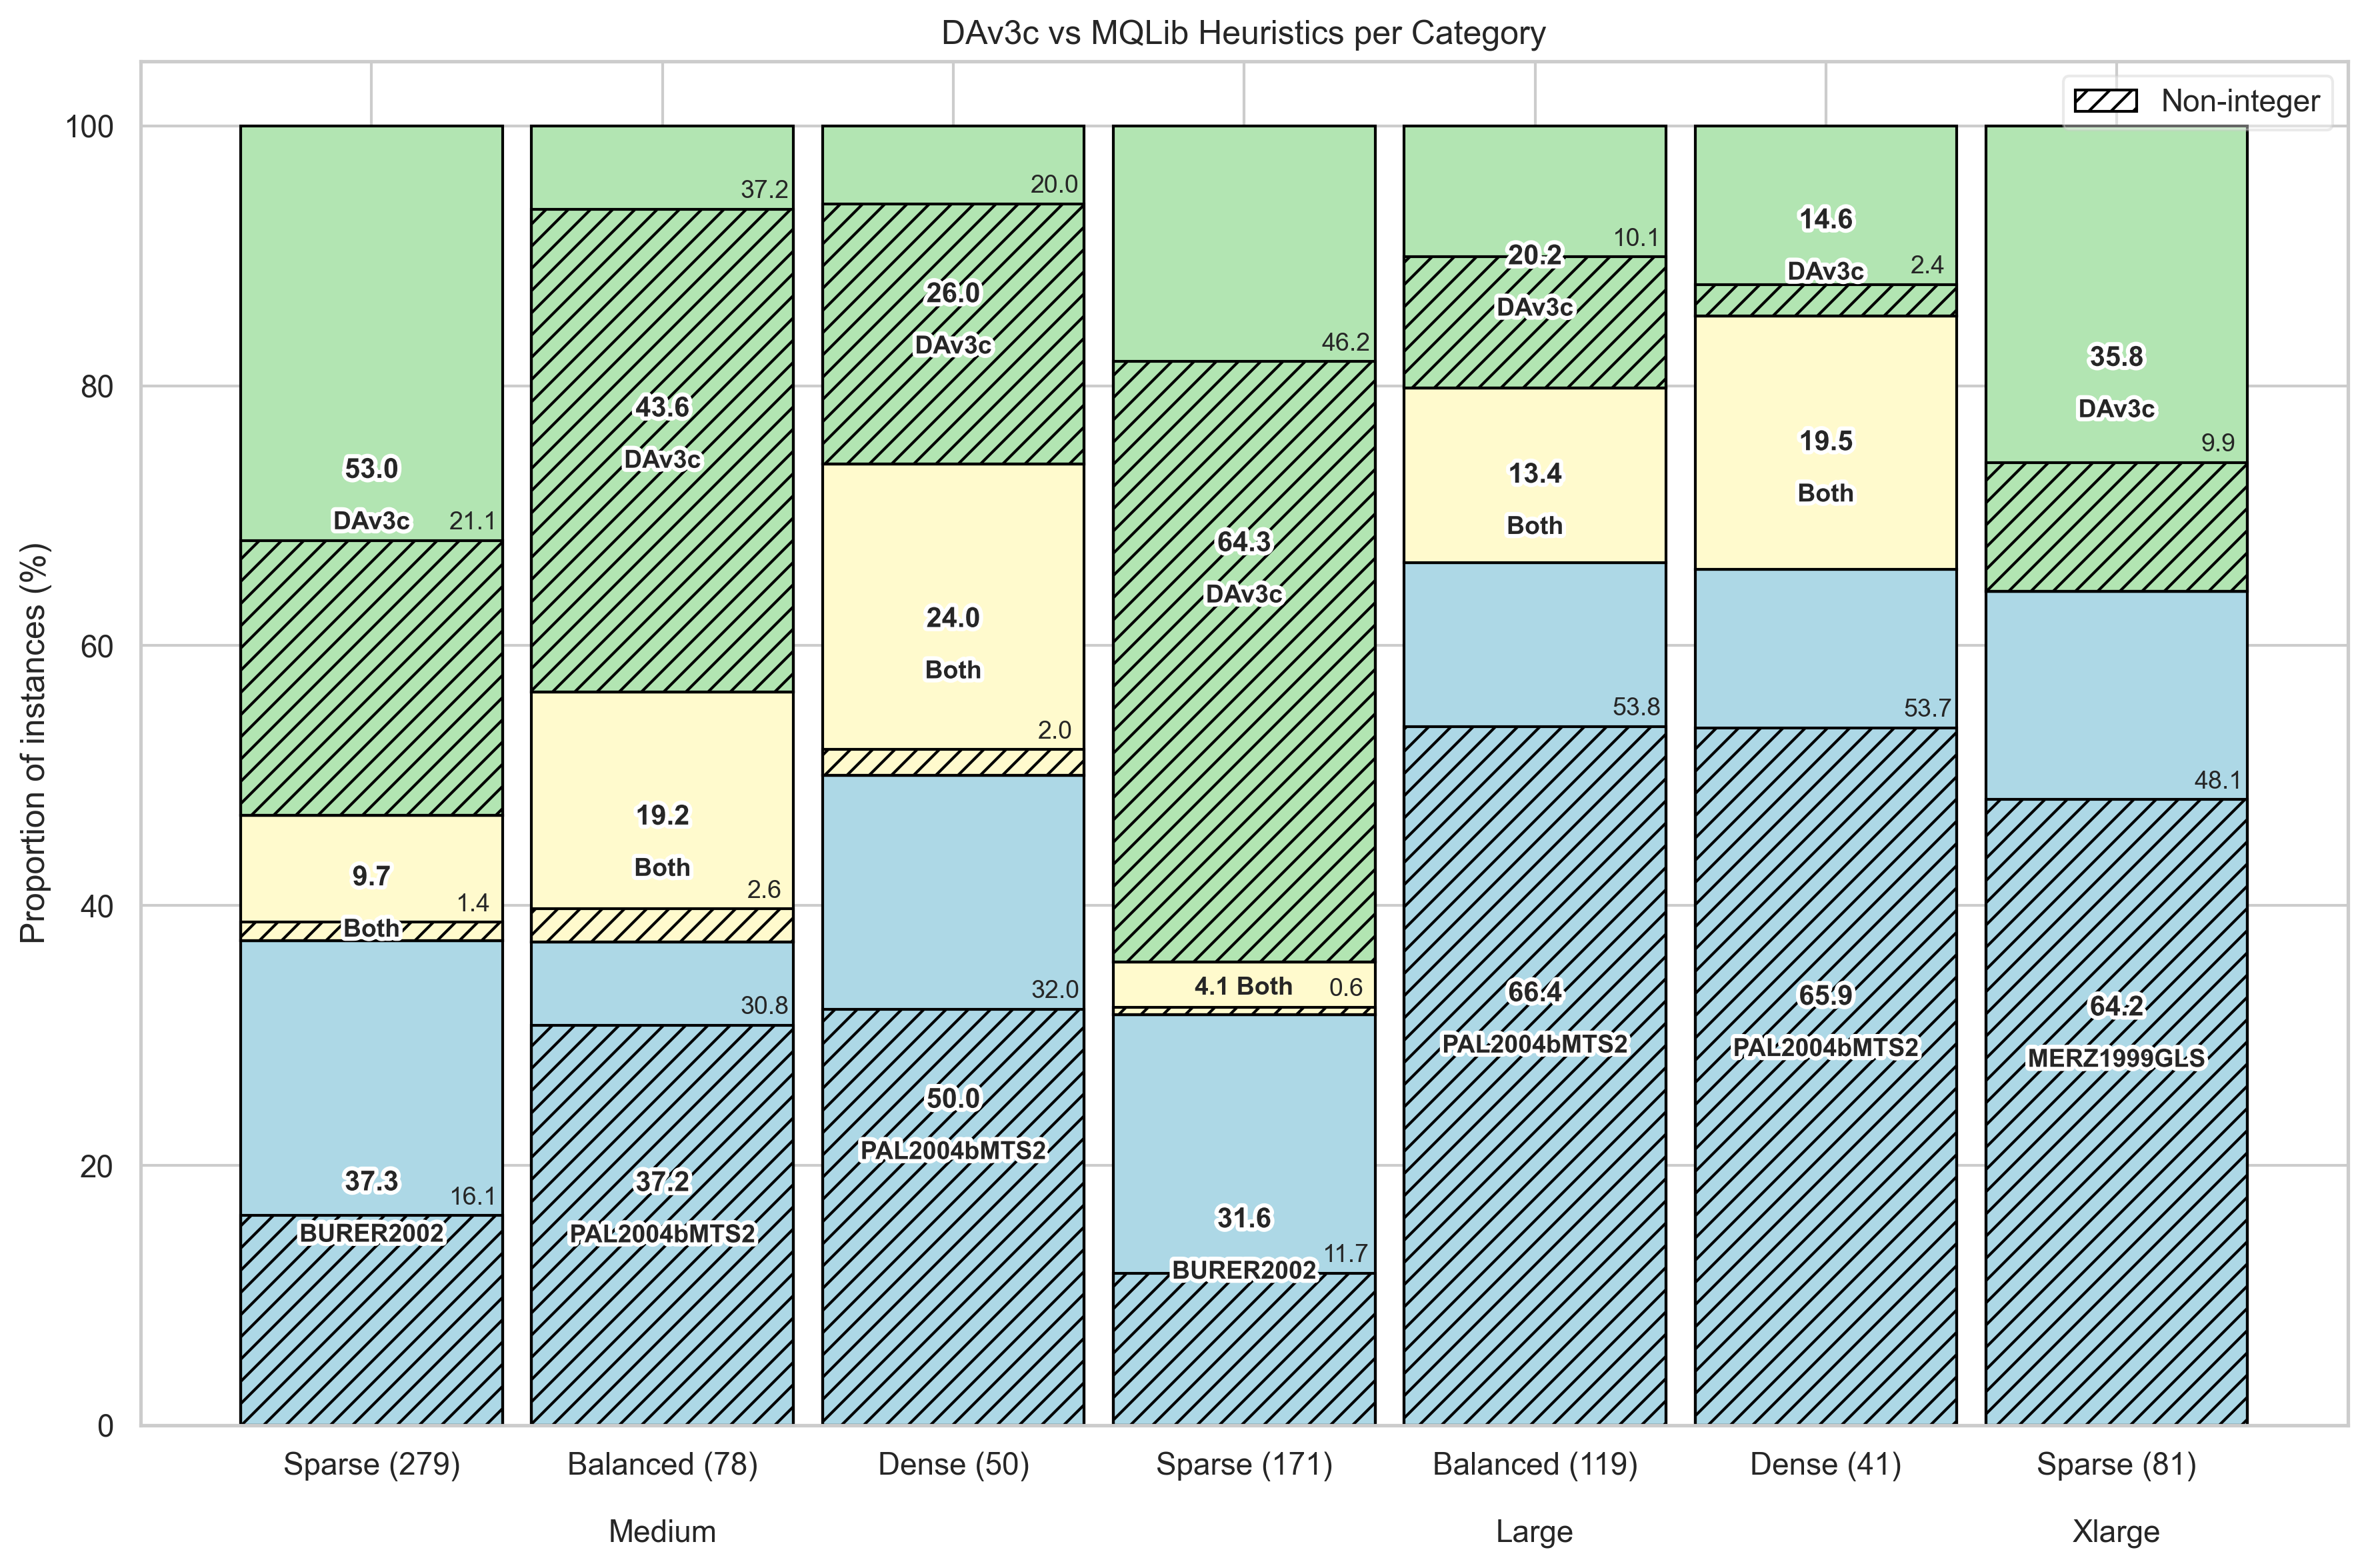

In [7]:
# Purpose: Render the category-wise outcome plot for DAv3c versus the MQLib heuristic.
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_heu,
    pivot_table=pivot_table_heu,
    title="DAv3c vs MQLib Heuristics per Category",
    win_label="DAv3c",
    loss_label="Heuristic",
    use_category_loss_labels=True,
    save_name="dav3c_vs_heuristics_category.pdf",
)

## 3.3 Cut-ratio frequency diagnostic

The cut-ratio summary complements win counts by examining **how close** the two objective values are. `tie_count` and `ratio_one_count` provide a consistency check under the utility's exact/approximate conventions. The saved PDF is a diagnostic figure, even when the conference paper does not reproduce it.

Validation check:
Tie count: 85
Ratio == 1.0: 85


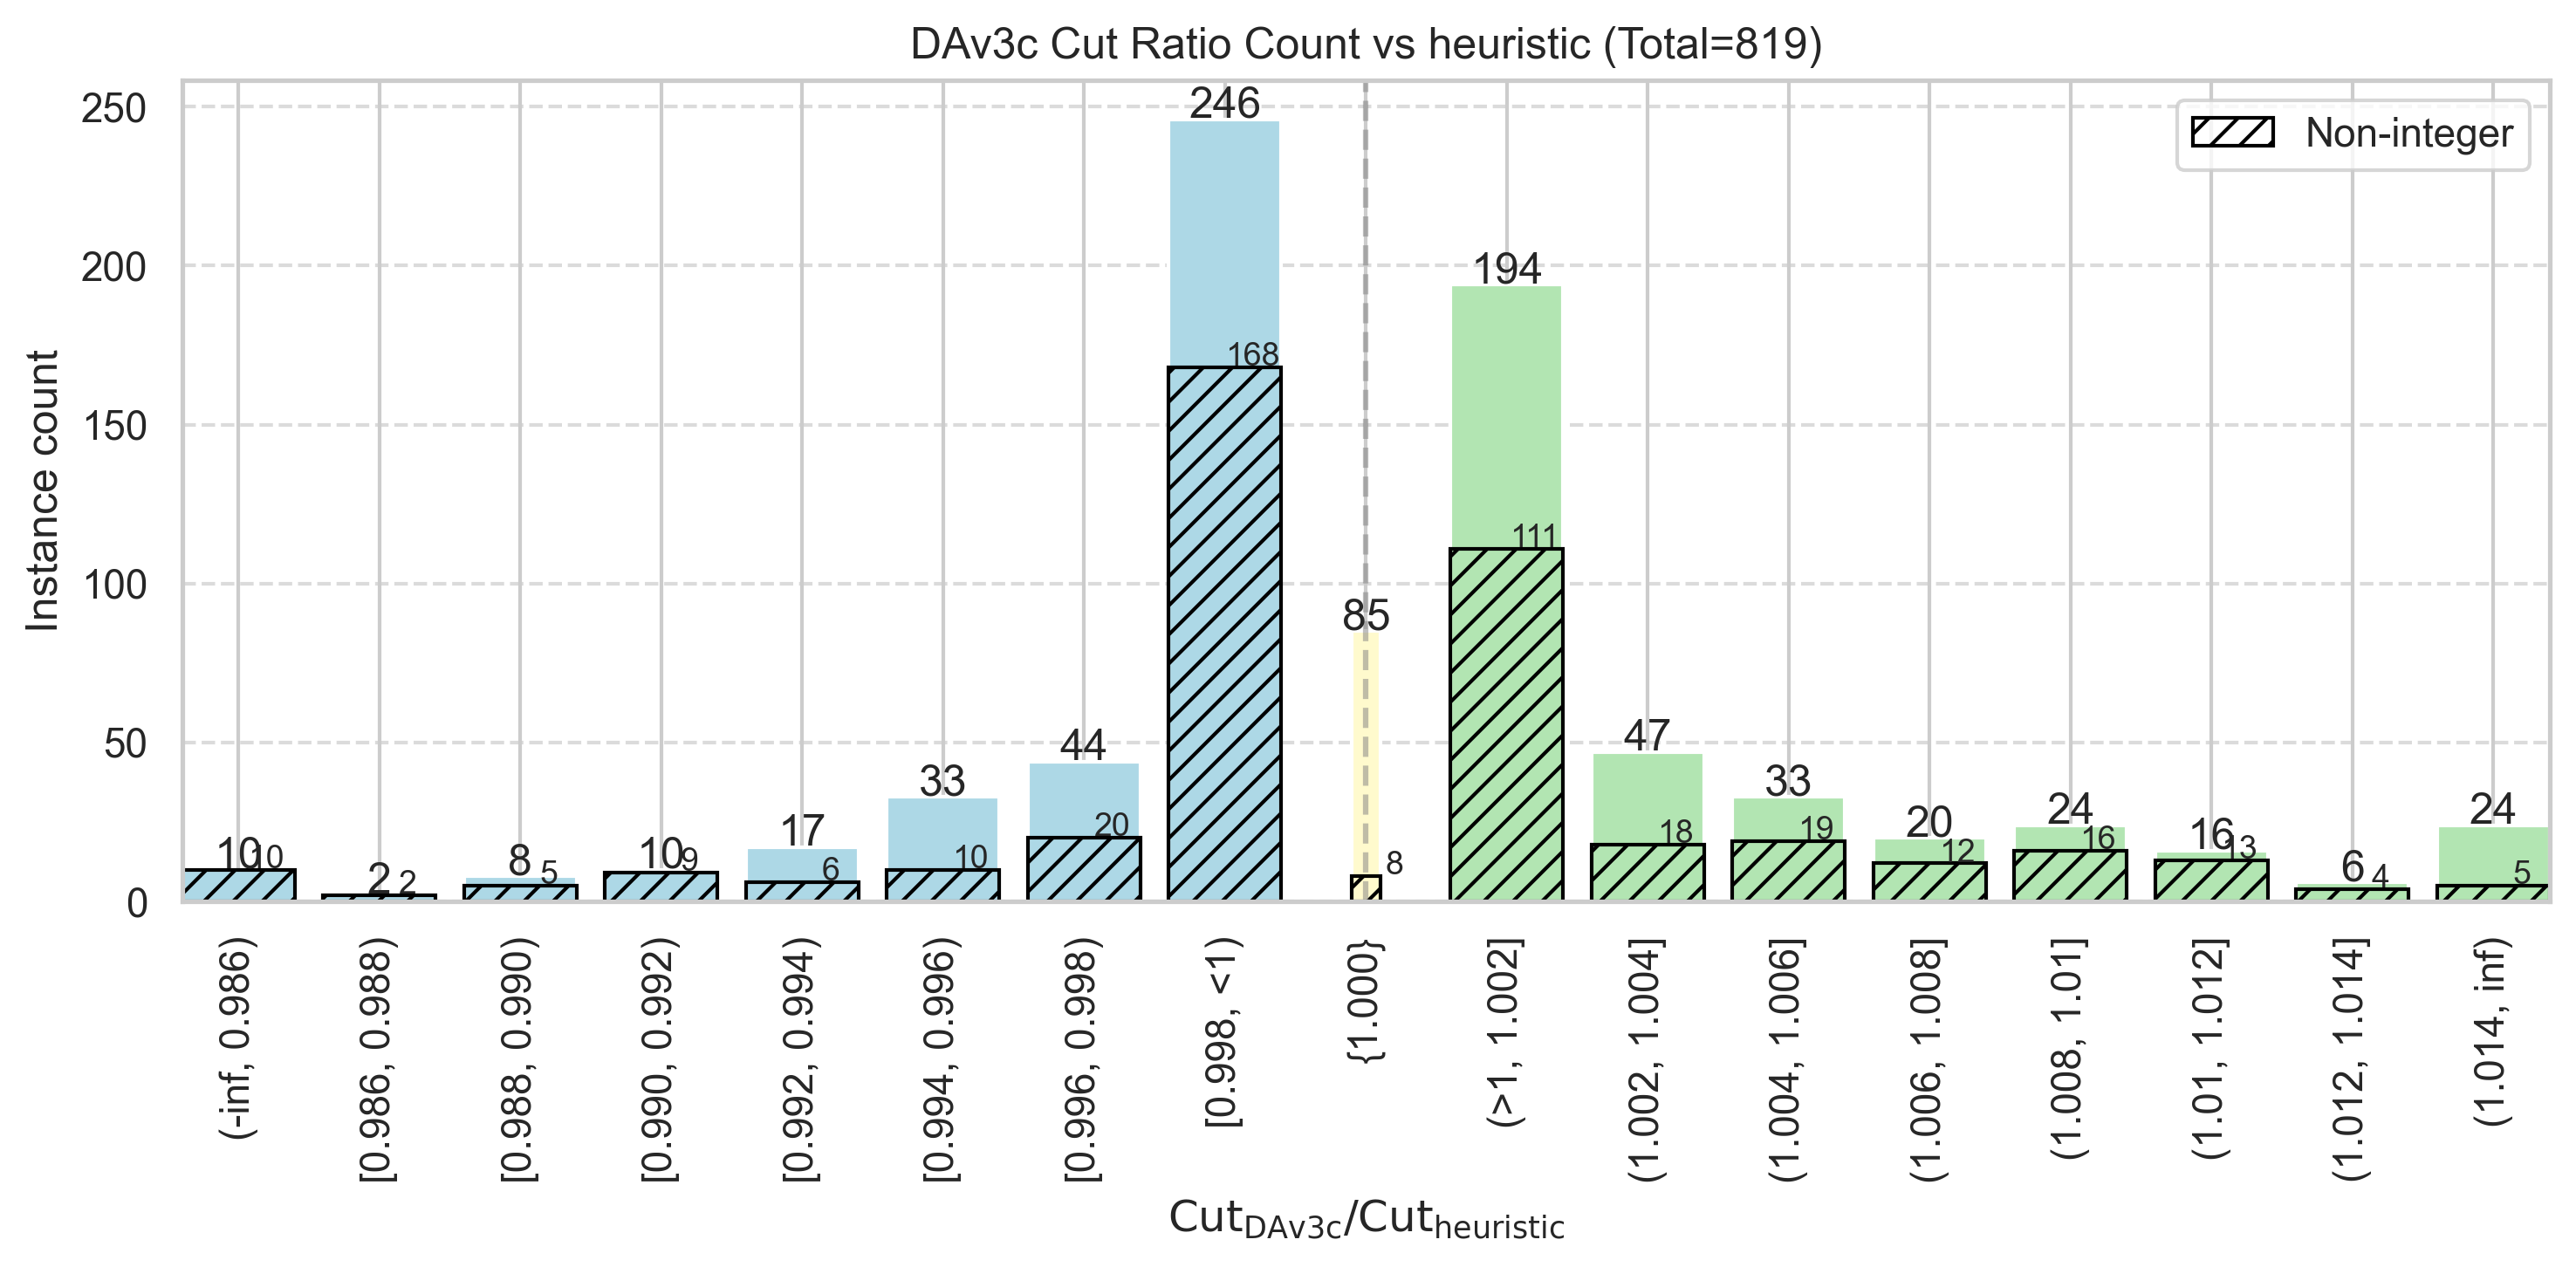

In [8]:
# Purpose: Count cut-ratio groups and check exact ratio-one frequencies against tie counts.
ratio_result_heu = utils.compute_cut_ratio_counts(
    df=df_heu,
    solver_col="DAv3c",
    baseline_col="heuristic",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_heu["tie_count"])
print("Ratio == 1.0:", ratio_result_heu["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_heu,
    solver_label="DAv3c",
    baseline_label="heuristic",
    save_path=cfg.FIGURE_DIR / "DAv3c_Heuristics_Cut_Ratio_Count.pdf",
)

## 3.4 Paired Wilcoxon tests and numerical-tie sensitivity

The first call performs the notebook's overall paired test. Subsequent tests work by size–density category and apply the utility's multiple-testing correction. The loop over `eps` checks whether treating very small absolute differences as ties changes the conclusions. For numerical interpretation, compare `n_nonzero`, `n_ties`, adjusted p-values, and effect sizes together.

In [9]:
# Purpose: Run the repository’s overall paired Wilcoxon comparison.
utils.run_wilcoxon(df_heu, "DAv3c", "heuristic", "DAv3c vs MQLib Heuristics")


=== DAv3c vs MQLib Heuristics ===
Total paired samples: 819
Numerical ties: 85
Samples used: 734
Wilcoxon statistic: 133771.5
p-value: 8.4806e-01
Rank-biserial correlation: -0.0082
Median difference: -4.23461e-09
Result: Not statistically significant (unadjusted)


{'n_total': 819,
 'n_nonzero': 734,
 'n_ties': 85,
 'stat': np.float64(133771.5),
 'p_raw': np.float64(0.8480572817359886),
 'r_rb': np.float64(-0.00816326530612245)}

In [10]:
# Purpose: Repeat category-level Wilcoxon tests under three absolute-difference tolerances.
eps_values = [0, 1e-9, 1e-8]

for eps in eps_values:
    results = utils.wilcoxon_by_category(
        df_heu,
        "DAv3c",
        "heuristic",
        eps=eps
    )

    print(f"\n=== Absolute tolerance: {eps} ===")

    display(
        results[
            [
                "category",
                "n_nonzero",
                "n_ties",
                "p_raw",
                "p_holm",
                "r_rb",
                "status"
            ]
        ]
    )


=== Absolute tolerance: 0 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,103,16,4.449840e-05,2.224920e-04,-0.463406,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,165,6,1.752789e-09,1.226952e-08,0.540270,Significant
3,medium_balanced,65,13,9.089513e-01,9.089513e-01,0.016317,Not significant
4,medium_dense,38,12,1.195506e-02,3.586517e-02,-0.462888,Significant
5,medium_sparse,256,23,1.207436e-02,3.586517e-02,0.180964,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant



=== Absolute tolerance: 1e-09 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,103,16,4.449840e-05,2.224920e-04,-0.463406,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,164,7,1.666406e-09,1.166484e-08,0.542646,Significant
3,medium_balanced,63,15,9.399703e-01,9.399703e-01,0.010913,Not significant
4,medium_dense,38,12,1.195506e-02,3.586517e-02,-0.462888,Significant
5,medium_sparse,252,27,1.279055e-02,3.586517e-02,0.180908,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant



=== Absolute tolerance: 1e-08 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,102,17,5.102457e-05,2.551228e-04,-0.462022,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,163,8,1.576246e-09,1.103372e-08,0.545114,Significant
3,medium_balanced,60,18,9.882530e-01,9.882530e-01,0.002186,Not significant
4,medium_dense,37,13,1.158695e-02,3.476084e-02,-0.470839,Significant
5,medium_sparse,252,27,1.279055e-02,3.476084e-02,0.180908,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant


In [11]:
# Purpose: Run the standard category-wise Holm-adjusted test and render its summary.
res_heu = utils.wilcoxon_by_category(df_heu, "DAv3c", "heuristic")
utils.print_wilcoxon_Pairwise_results(res_heu , "DAv3c vs MQLib Heuristic (Category-wise)")


=== DAv3c vs MQLib Heuristic (Category-wise) ===
large_balanced       | n=103 | ties= 16 | p_raw=4.4498e-05 | p_holm=2.2249e-04 | r_rb=-0.463 | Significant
large_dense          | n= 33 | ties=  8 | p_raw=1.0992e-04 | p_holm=4.3967e-04 | r_rb=-0.729 | Significant
large_sparse         | n=164 | ties=  7 | p_raw=1.6664e-09 | p_holm=1.1665e-08 | r_rb=+0.543 | Significant
medium_balanced      | n= 63 | ties= 15 | p_raw=9.3997e-01 | p_holm=9.3997e-01 | r_rb=+0.011 | Not significant
medium_dense         | n= 38 | ties= 12 | p_raw=1.1955e-02 | p_holm=3.5865e-02 | r_rb=-0.463 | Significant
medium_sparse        | n=252 | ties= 27 | p_raw=1.2791e-02 | p_holm=3.5865e-02 | r_rb=+0.181 | Significant
xlarge_sparse        | n= 81 | ties=  0 | p_raw=1.9579e-06 | p_holm=1.1748e-05 | r_rb=-0.609 | Significant


## 4. DAv3c versus DAv3

The same `df_dav3` population is reused for the CPU-based DAv3c versus hardware-based DAv3 comparison. The `result` and summary variables used earlier are **overwritten intentionally**; only the current pair is represented by subsequent plots and tests. Do not read these as pooled comparisons.

In [14]:
# Purpose: Replace the result column with DAv3c-versus-DAv3 outcomes.
df_dav3['result'] = df_dav3.apply(lambda row: utils.compare_scores(row["DAv3c"], row["DAv3"]), axis=1)
pivot_table_dav3, summary_dav3 = utils.conparison_summary(df_dav3)
print(pivot_table_dav3)

result         category int_only   loss   tie   win weight_type  total
0         medium_sparse    False   84.0   5.0  19.0       float  108.0
1         medium_sparse     True  103.0  43.0  25.0     integer  171.0
14        medium_sparse    total  187.0  48.0  44.0       total  279.0
2       medium_balanced    False   33.0   3.0  19.0       float   55.0
3       medium_balanced     True    9.0  14.0   0.0     integer   23.0
15      medium_balanced    total   42.0  17.0  19.0       total   78.0
4          medium_dense    False   21.0   1.0   5.0       float   27.0
5          medium_dense     True   12.0  11.0   0.0     integer   23.0
16         medium_dense    total   33.0  12.0   5.0       total   50.0
6          large_sparse    False   49.0   1.0  50.0       float  100.0
7          large_sparse     True   59.0  11.0   1.0     integer   71.0
17         large_sparse    total  108.0  12.0  51.0       total  171.0
8        large_balanced    False   63.0   0.0  13.0       float   76.0
9     

In [15]:
# Purpose: Display the updated summary, now for DAv3c versus DAv3.
print(summary_dav3)

{'medium_sparse_flt': (84.0, 5.0, 19.0), 'medium_sparse': (187.0, 48.0, 44.0), 'medium_balanced_flt': (33.0, 3.0, 19.0), 'medium_balanced': (42.0, 17.0, 19.0), 'medium_dense_flt': (21.0, 1.0, 5.0), 'medium_dense': (33.0, 12.0, 5.0), 'large_sparse_flt': (49.0, 1.0, 50.0), 'large_sparse': (108.0, 12.0, 51.0), 'large_balanced_flt': (63.0, 0.0, 13.0), 'large_balanced': (83.0, 23.0, 13.0), 'large_dense_flt': (20.0, 0.0, 3.0), 'large_dense': (28.0, 10.0, 3.0), 'xlarge_sparse_flt': (15.0, 0.0, 32.0), 'xlarge_sparse': (20.0, 0.0, 61.0)}


(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs DAv3 per Category'}, ylabel='Proportion of instances (%)'>)

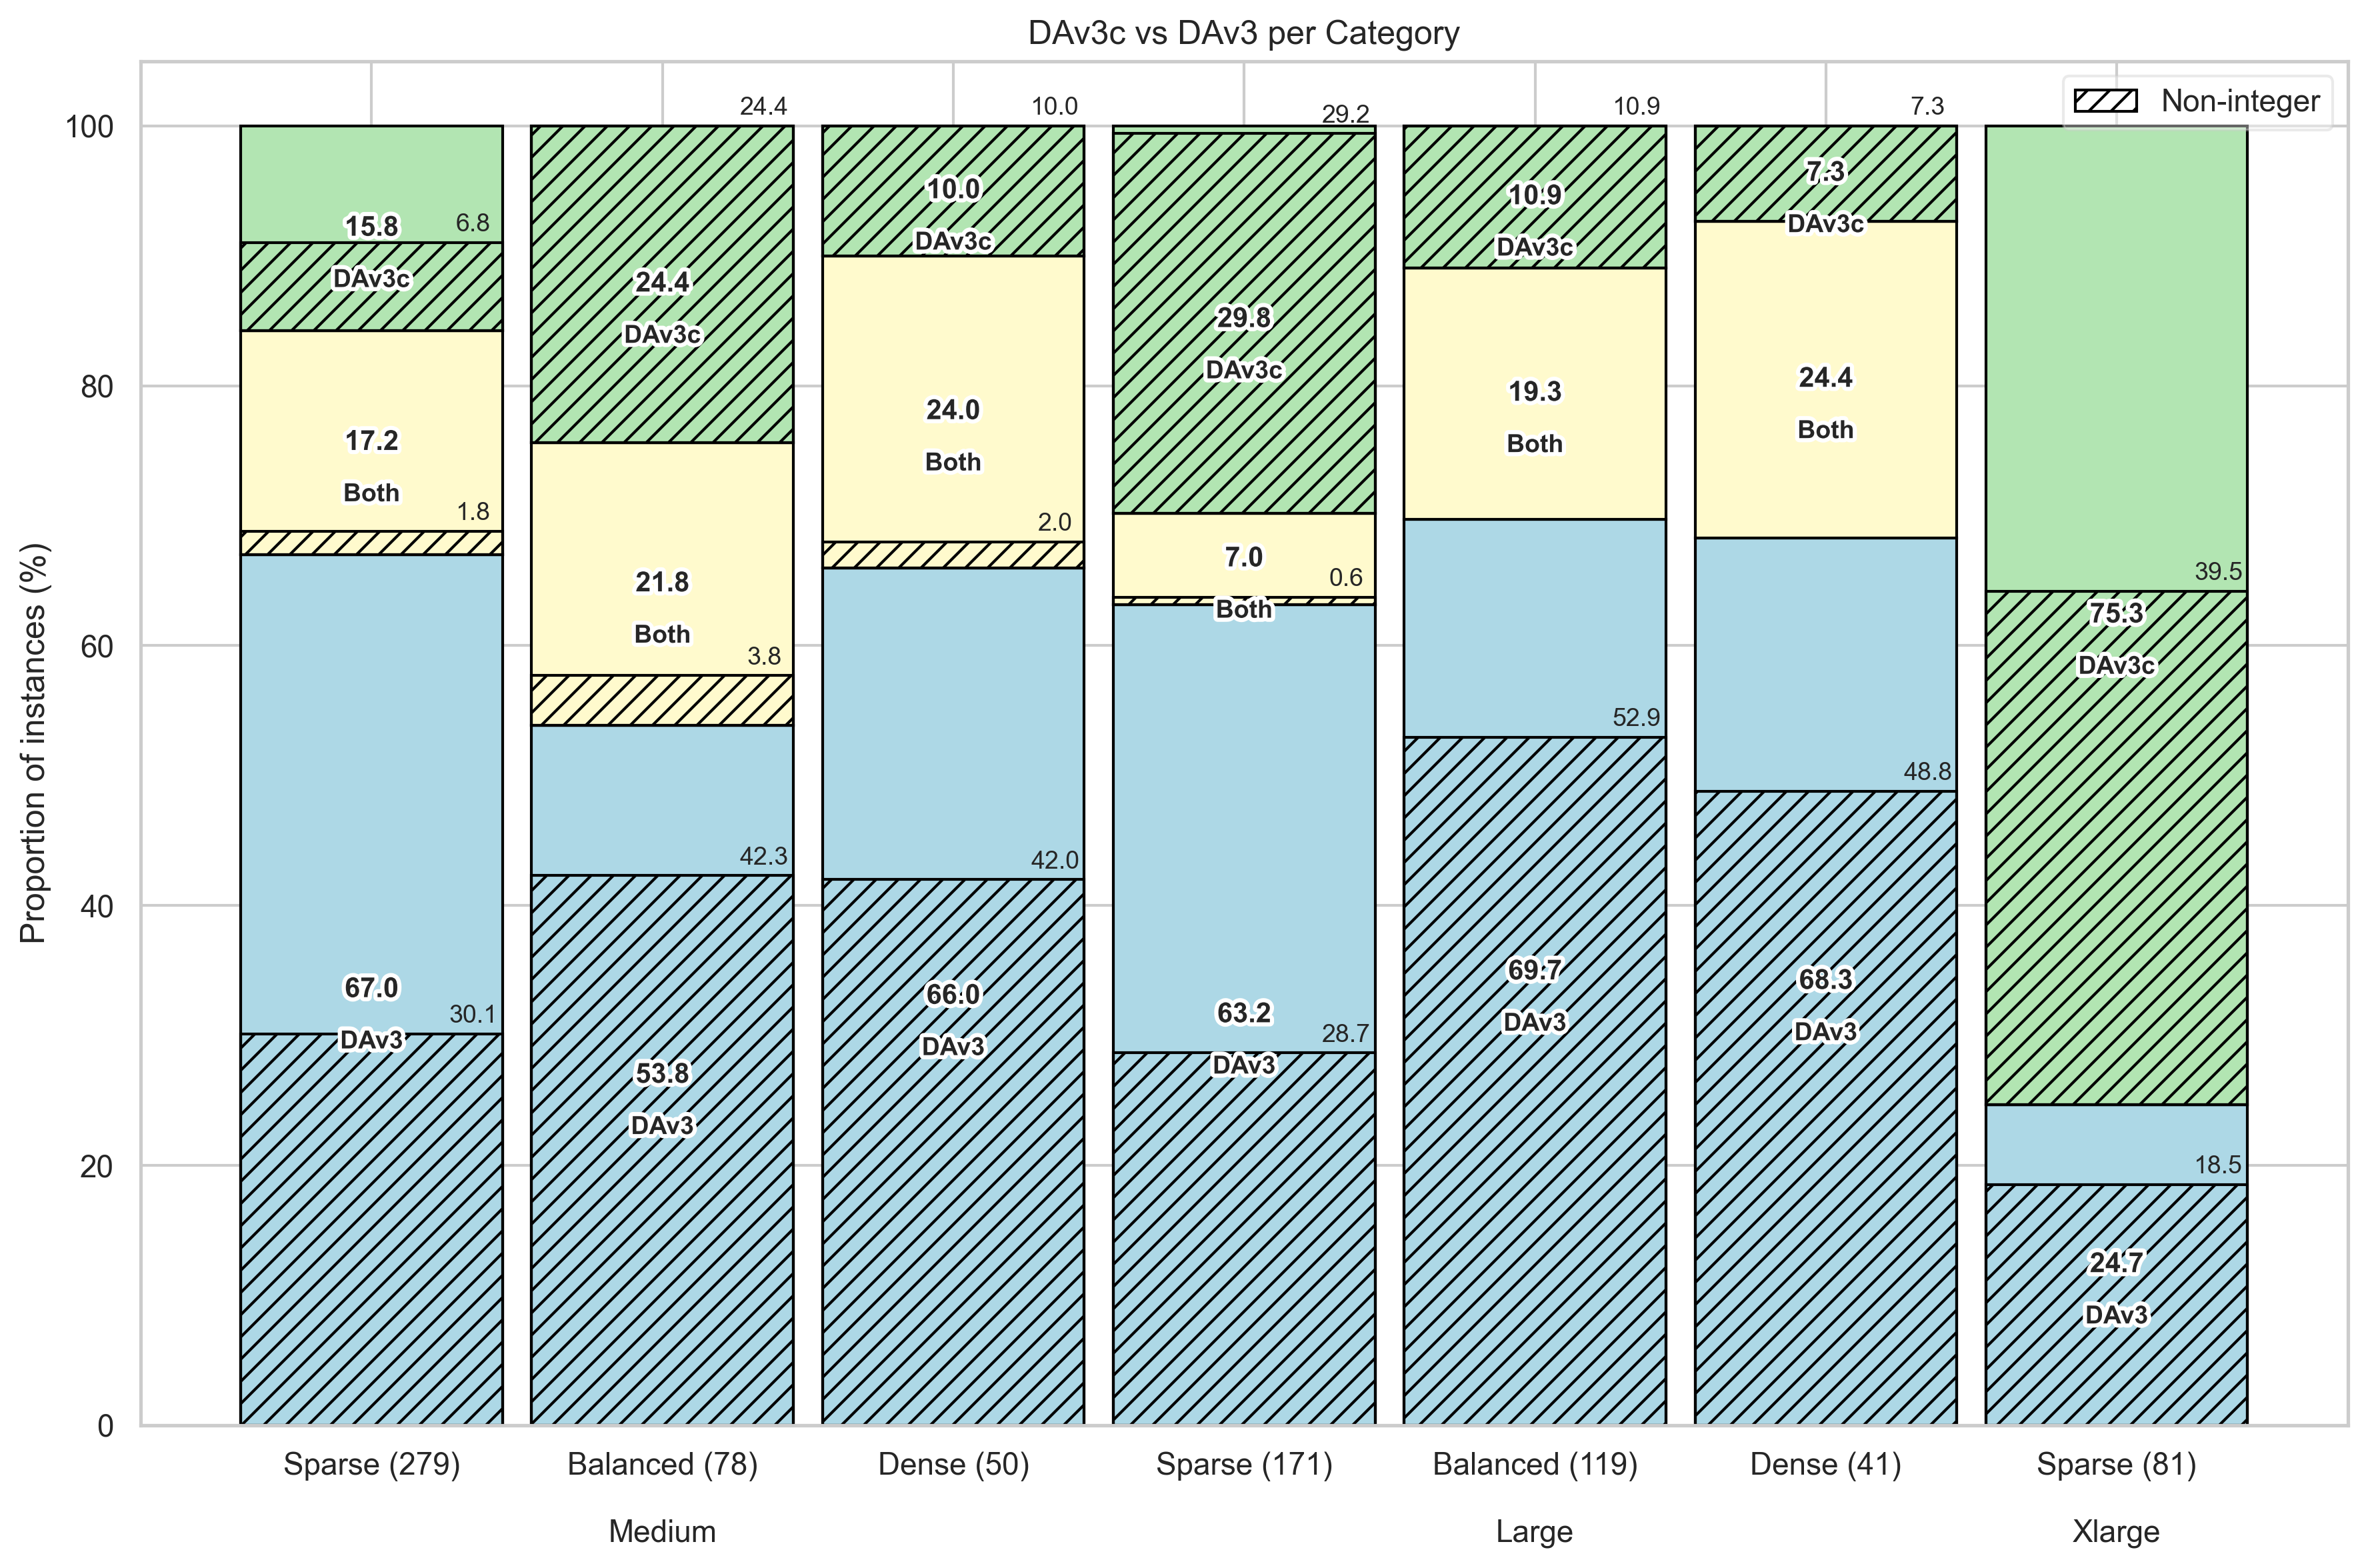

In [16]:
# Purpose: Render category-wise DAv3c-vs-DAv3 win/tie/loss.
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_dav3,
    pivot_table=pivot_table_dav3,
    title="DAv3c vs DAv3 per Category",
    win_label="DAv3c",
    loss_label="DAv3",
    use_category_loss_labels=False,
    save_name="dav3c_vs_dav3_category.pdf",
)

## 5.1 XLarge exclusion diagnostic and cut ratios

The next cell creates `df_dav3_new` with XLarge excluded for a possible common-size sensitivity analysis. In the original notebook, the following cut-ratio call used `df_dav3`, not `df_dav3_new`. Here that **original full-population call is preserved** and labeled explicitly, so the diagnostic does not silently change its sample. The complete ratio is recalculated again afterward; both original calls are retained.

In [17]:
# Purpose: Create a non-XLarge subset; the subsequent original ratio code uses the full dataset.
df_dav3_new = df_dav3[df_dav3['size_cat'] != 'xlarge'].copy()

Validation check:
Tie count: 122
Ratio == 1.0: 122


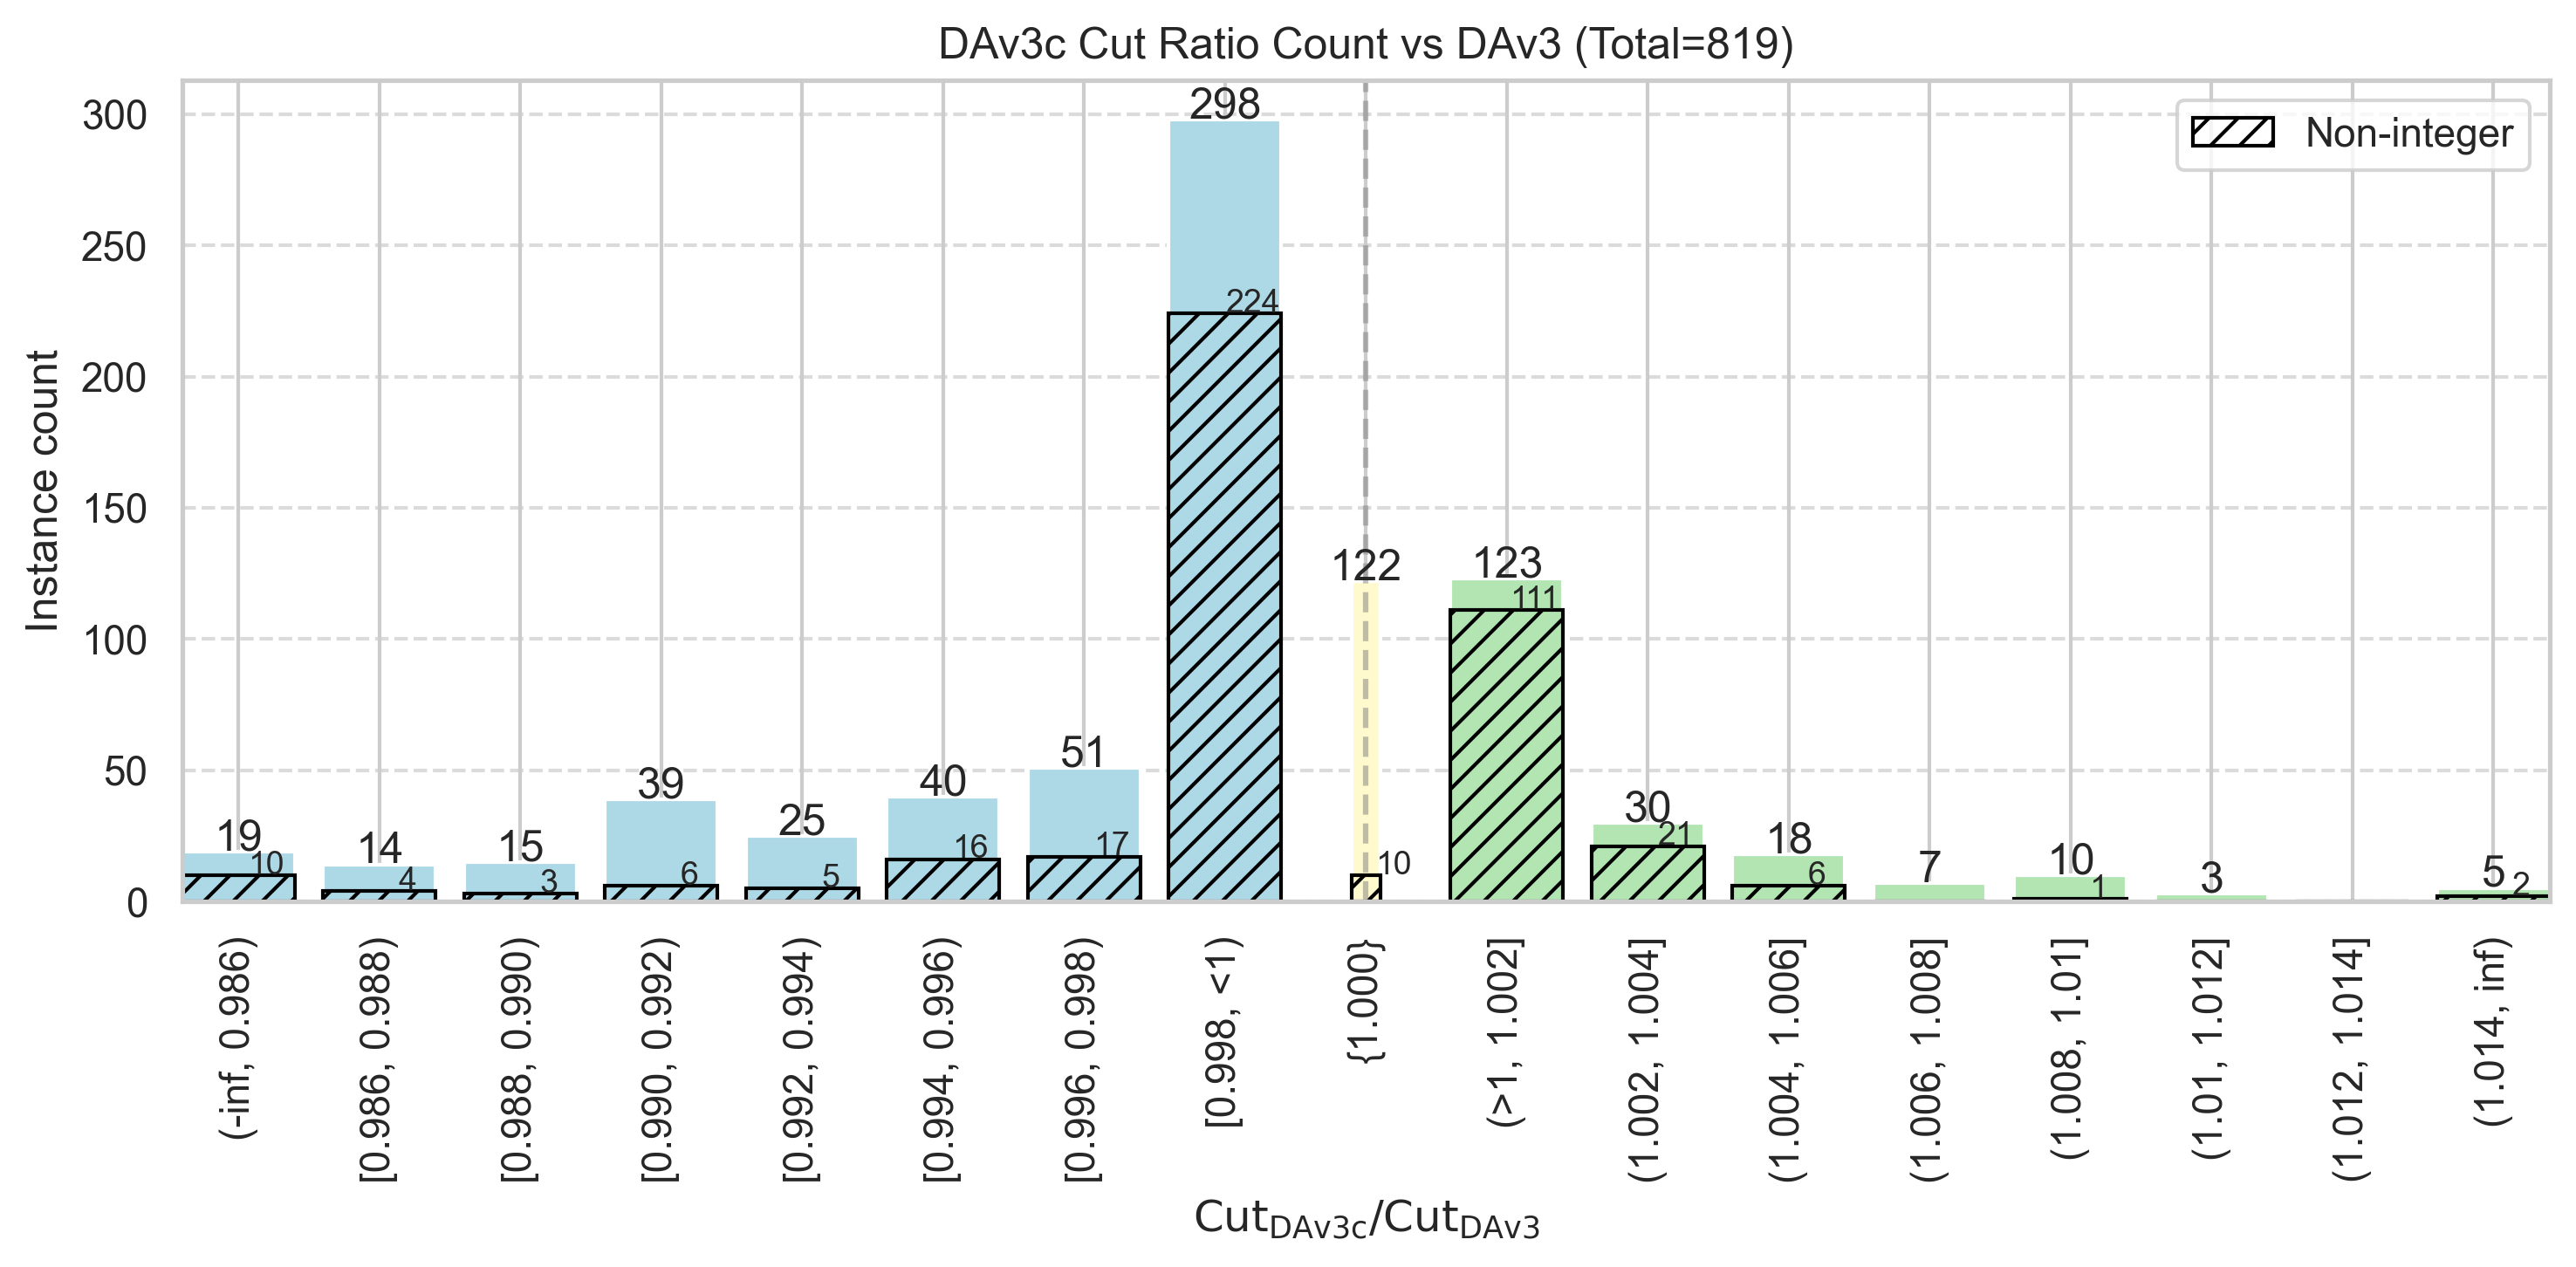

In [18]:
# Purpose: Original full-population cut-ratio diagnostic despite the `_new` variable name.
ratio_result_dav3_new = utils.compute_cut_ratio_counts(
    df=df_dav3 ,
    solver_col="DAv3c",
    baseline_col="DAv3",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav3_new["tie_count"])
print("Ratio == 1.0:", ratio_result_dav3_new["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav3_new,
    solver_label="DAv3c",
    baseline_label="DAv3",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv3_Cut_Ratio_Count.pdf",
)

Validation check:
Tie count: 122
Ratio == 1.0: 122


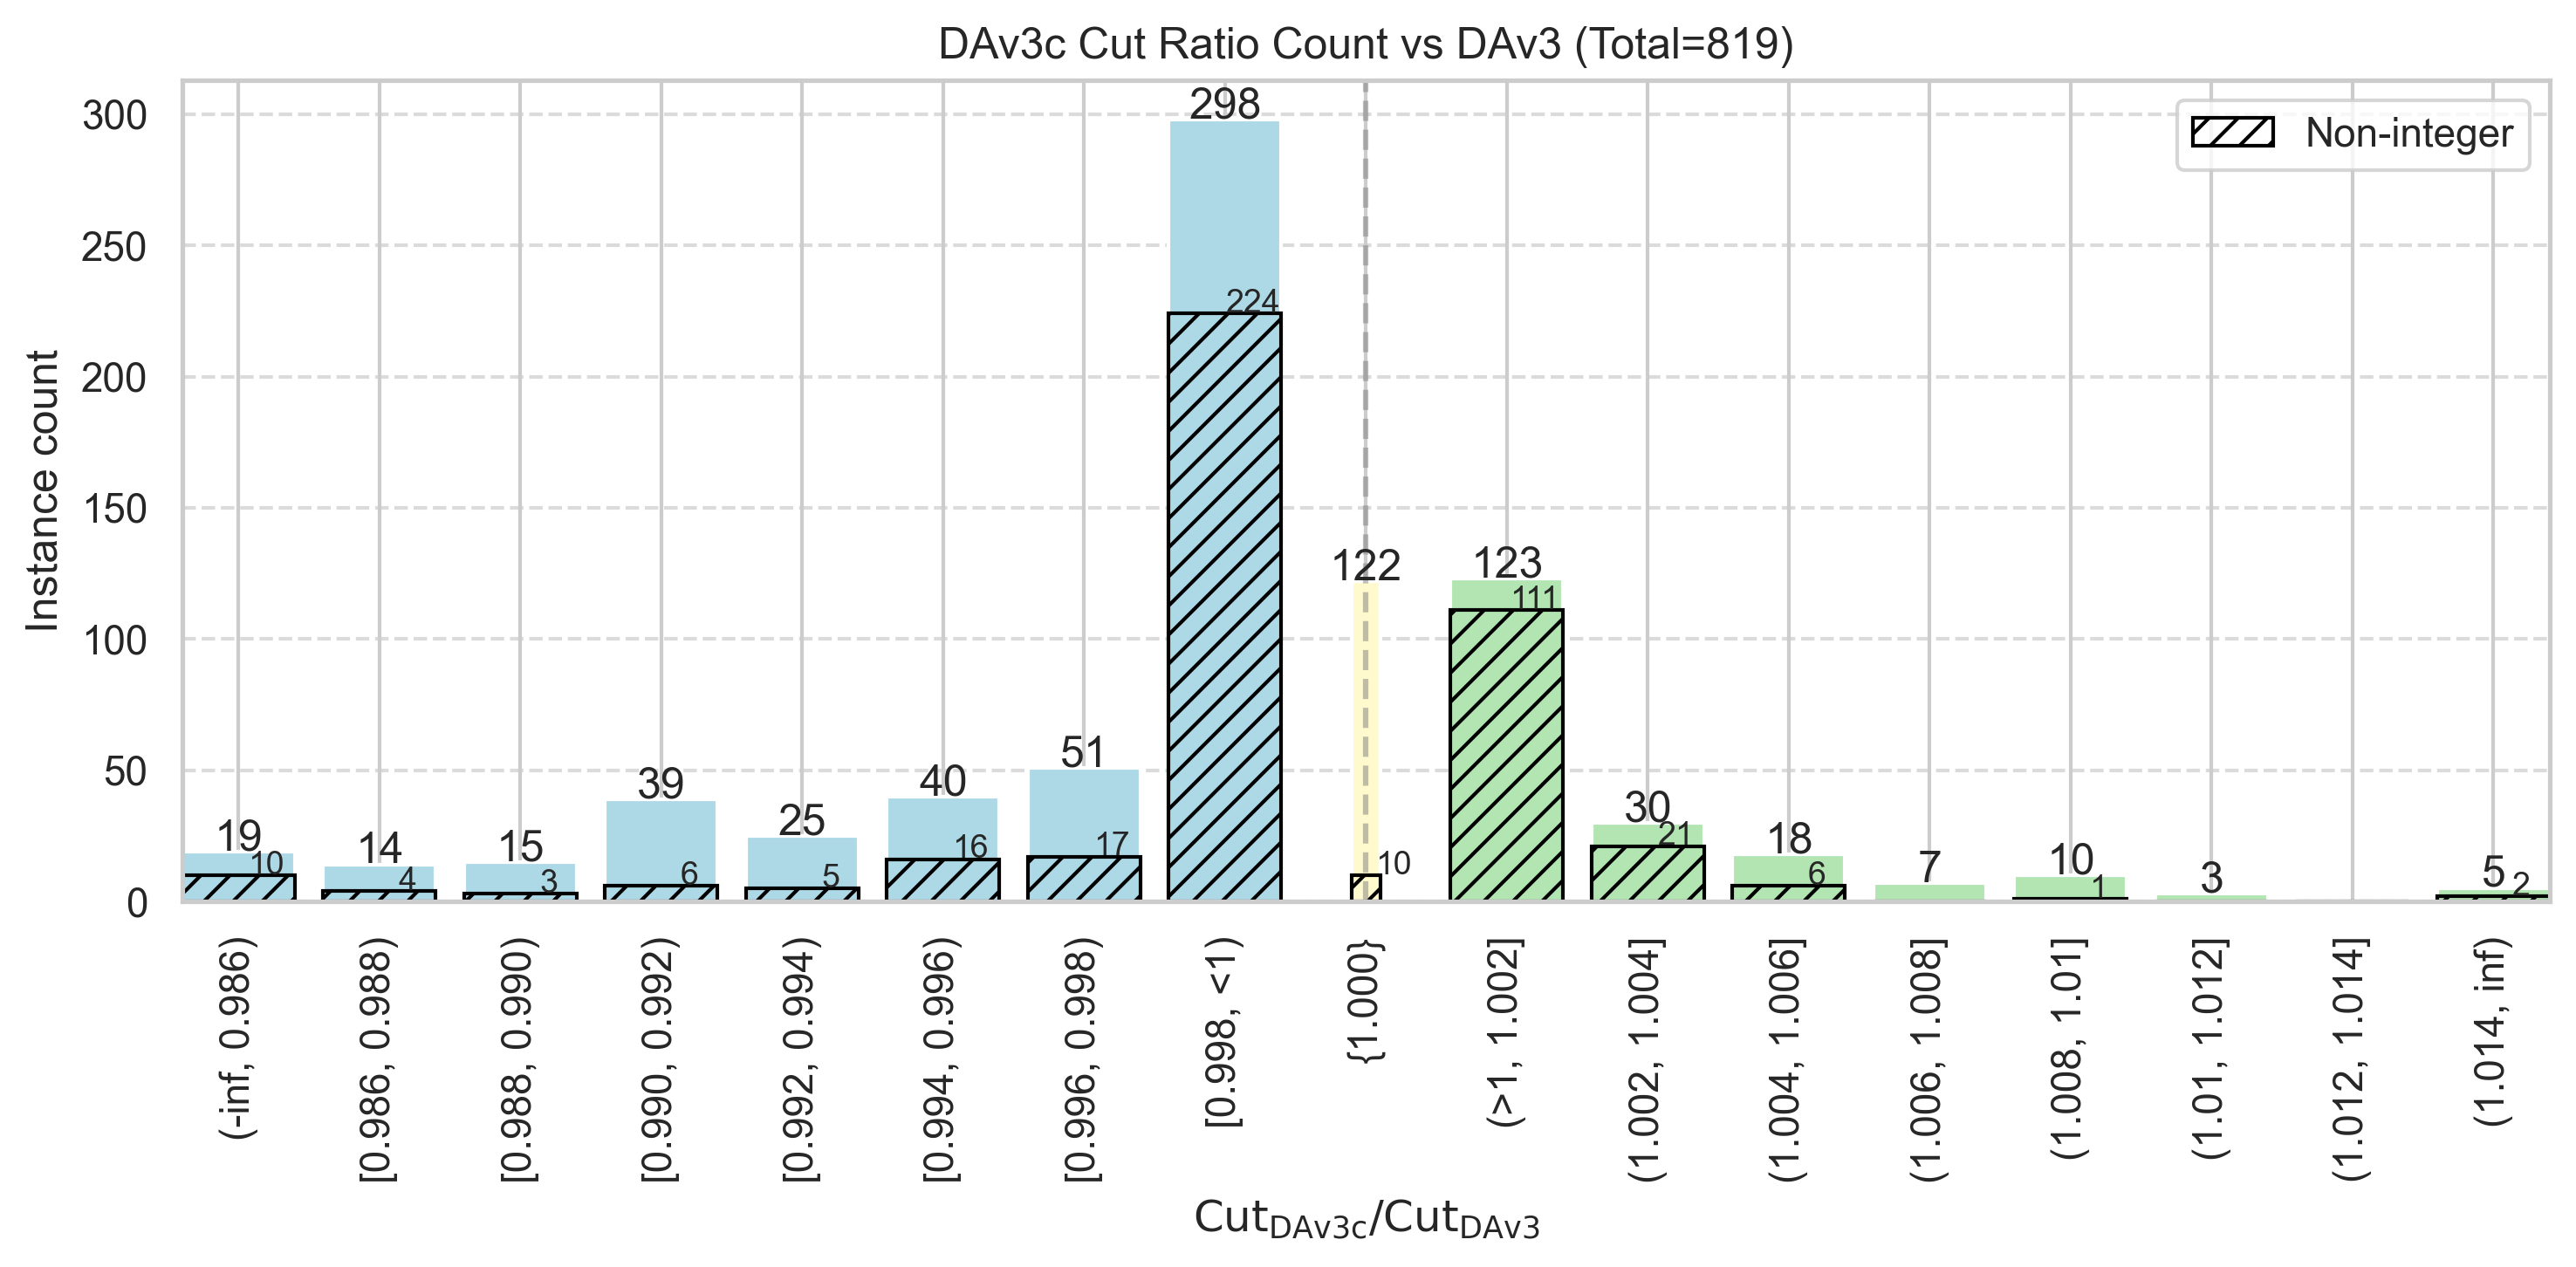

In [19]:
# Purpose: Repeat the complete DAv3c-vs-DAv3 ratio calculation and validation.
ratio_result_dav3 = utils.compute_cut_ratio_counts(
    df=df_dav3,
    solver_col="DAv3c",
    baseline_col="DAv3",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav3["tie_count"])
print("Ratio == 1.0:", ratio_result_dav3["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav3,
    solver_label="DAv3c",
    baseline_label="DAv3",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv3_Cut_Ratio_Count.svg",
)

## 5.2 DAv3c–DAv3 significance and sensitivity

Interpret the direction of the signed-rank effect consistently: positive relative to the first solver (`DAv3c`), negative relative to `DAv3`. Holm-adjusted tests determine whether observed paired differences are statistically distinguishable from zero within the tested family, not whether one system is universally superior.

In [20]:
# Purpose: Run the overall paired test for DAv3c versus DAv3.
utils.run_wilcoxon(df_dav3, "DAv3c", "DAv3", "DAv3c vs DAv3")


=== DAv3c vs DAv3 ===
Total paired samples: 819
Numerical ties: 122
Samples used: 697
Wilcoxon statistic: 78120.0
p-value: 2.8052e-16
Rank-biserial correlation: -0.3577
Median difference: -83.7511
Result: Statistically significant (unadjusted)


{'n_total': 819,
 'n_nonzero': 697,
 'n_ties': 122,
 'stat': np.float64(78120.0),
 'p_raw': np.float64(2.8052213788537224e-16),
 'r_rb': np.float64(-0.3577057631355009)}

In [21]:
# Purpose: Report the category-specific DAv3c-vs-DAv3 Wilcoxon tests.
res_dav3 = utils.wilcoxon_by_category(df_dav3, "DAv3c", "DAv3")
utils.print_wilcoxon_Pairwise_results(res_dav3 , "DAv3c vs DAv3 (Category-wise)")


=== DAv3c vs DAv3 (Category-wise) ===
large_balanced       | n= 96 | ties= 23 | p_raw=5.0163e-11 | p_holm=3.5114e-10 | r_rb=-0.772 | Significant
large_dense          | n= 31 | ties= 10 | p_raw=2.2119e-06 | p_holm=8.8476e-06 | r_rb=-0.875 | Significant
large_sparse         | n=159 | ties= 12 | p_raw=5.7383e-04 | p_holm=5.7383e-04 | r_rb=-0.315 | Significant
medium_balanced      | n= 61 | ties= 17 | p_raw=8.6590e-05 | p_holm=1.7318e-04 | r_rb=-0.578 | Significant
medium_dense         | n= 38 | ties= 12 | p_raw=4.6266e-07 | p_holm=2.3133e-06 | r_rb=-0.849 | Significant
medium_sparse        | n=231 | ties= 48 | p_raw=8.5845e-11 | p_holm=5.1507e-10 | r_rb=-0.493 | Significant
xlarge_sparse        | n= 81 | ties=  0 | p_raw=4.9881e-05 | p_holm=1.4964e-04 | r_rb=+0.519 | Significant


## 6. DAv3c versus DAv2

The DAv2 comparison uses a DAv2-eligible subset (`utils.filter_main_instances(..., "DAv2")`), which does not include XLarge. The same win–tie–loss, ratio, and Wilcoxon procedures are applied. Because populations differ, avoid directly comparing raw win counts across Sections 3–6 without checking the denominators.

In [22]:
# Purpose: Select DAv2-eligible rows for the DAv3c-versus-DAv2 comparison.
df_dav2 = utils.filter_main_instances(df_baseline,'DAv2')
df_dav2["category"] = (df_dav2["size_cat"] + "_" + df_dav2["density_cat"])
print(f'Total Number of Instances: {len(df_dav2)}')
print('............')
print(f"Size Category Distribution: {df_dav2['size_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_dav2['density_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_dav2['category'].value_counts()}")

Total Number of Instances: 738
............
Size Category Distribution: size_cat
medium    407
large     331
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      450
balanced    197
dense        91
Name: count, dtype: int64
............
Density Category Distribution: category
medium_sparse      279
large_sparse       171
large_balanced     119
medium_balanced     78
medium_dense        50
large_dense         41
Name: count, dtype: int64


In [23]:
# Purpose: Compute per-instance DAv3c-versus-DAv2 outcomes and aggregate them.
df_dav2['result'] = df_dav2.apply(lambda row: utils.compare_scores(row["DAv3c"], row["DAv2"]), axis=1)
pivot_table_dav2, summary_dav2 = utils.conparison_summary(df_dav2)
print(pivot_table_dav2)
print(summary_dav2)

result         category int_only   loss   tie   win weight_type  total
0         medium_sparse    False   75.0   5.0  28.0       float  108.0
1         medium_sparse     True  117.0  35.0  19.0     integer  171.0
12        medium_sparse    total  192.0  40.0  47.0       total  279.0
2       medium_balanced    False   30.0   1.0  24.0       float   55.0
3       medium_balanced     True    9.0   9.0   5.0     integer   23.0
13      medium_balanced    total   39.0  10.0  29.0       total   78.0
4          medium_dense    False   22.0   0.0   5.0       float   27.0
5          medium_dense     True   12.0   6.0   5.0     integer   23.0
14         medium_dense    total   34.0   6.0  10.0       total   50.0
6          large_sparse    False   41.0   1.0  58.0       float  100.0
7          large_sparse     True   58.0   9.0   4.0     integer   71.0
15         large_sparse    total   99.0  10.0  62.0       total  171.0
8        large_balanced    False   45.0   0.0  31.0       float   76.0
9     

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs DAv2 per Category'}, ylabel='Proportion of instances (%)'>)

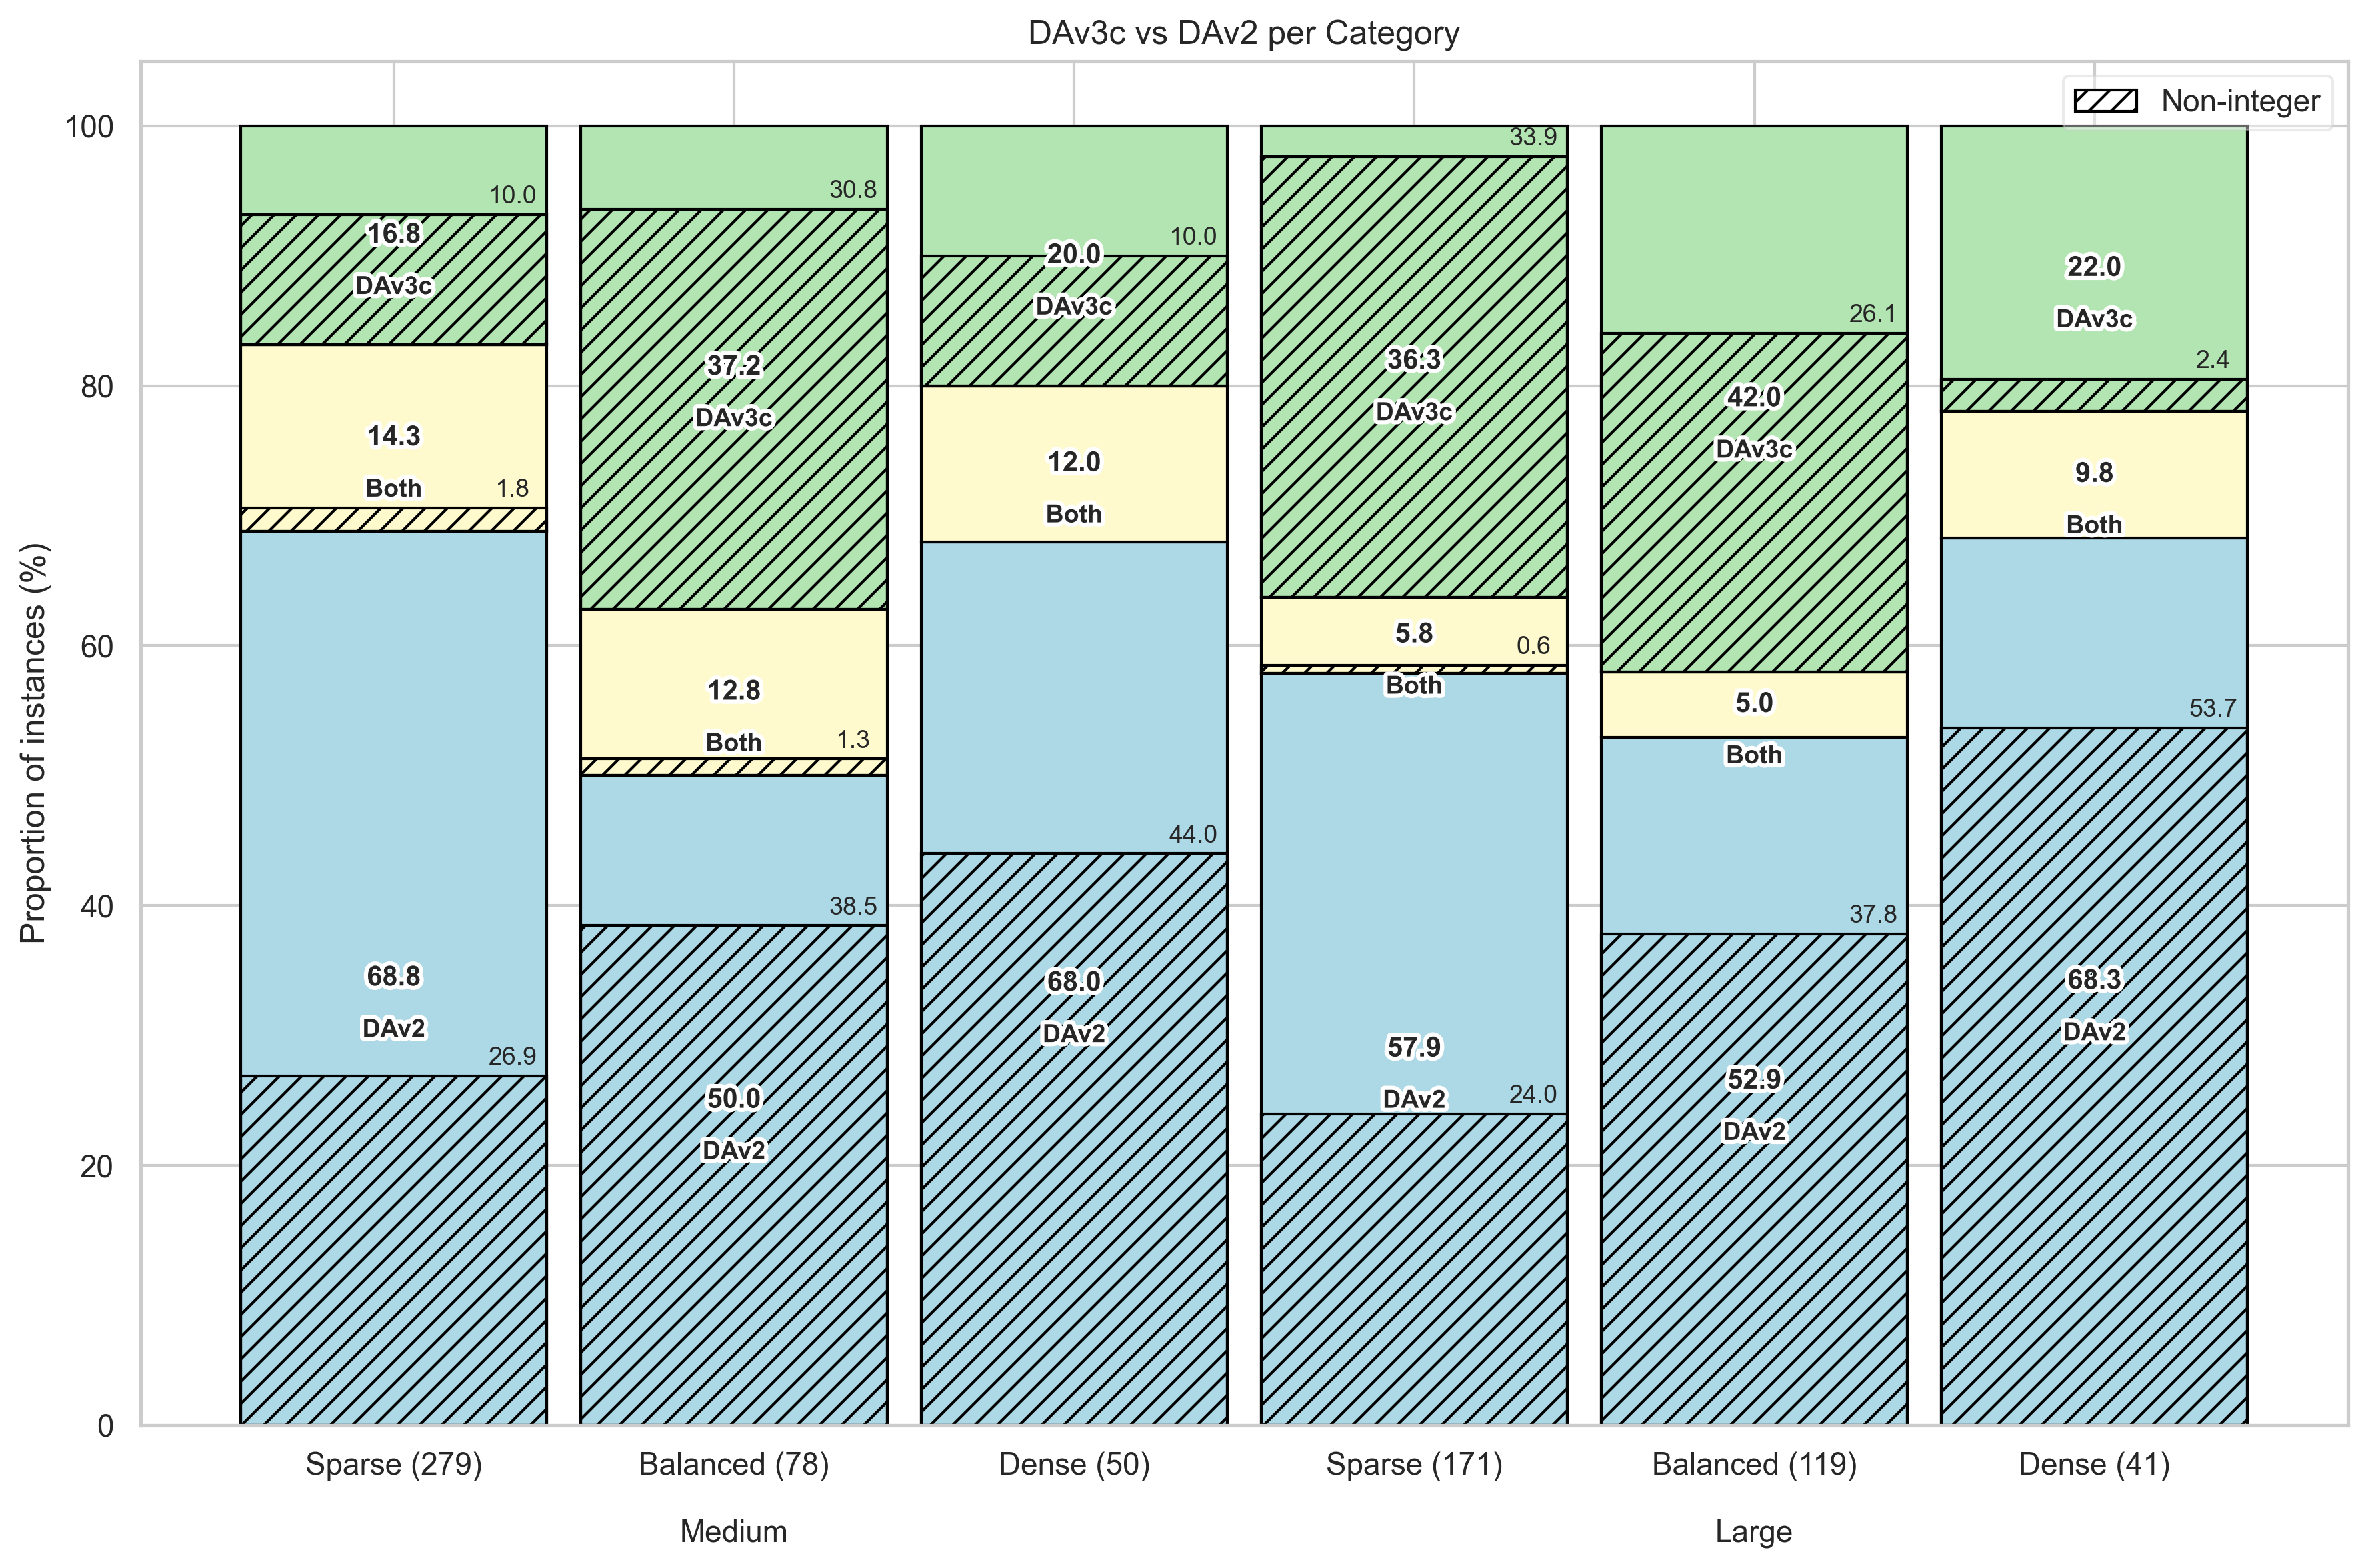

In [24]:
# Purpose: Plot category-level DAv3c-vs-DAv2 win/tie/loss.
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_dav2,
    pivot_table=pivot_table_dav2,
    title="DAv3c vs DAv2 per Category",
    win_label="DAv3c",
    loss_label="DAv2",
    use_category_loss_labels=False,
    save_name="dav3c_vs_dav2_category.pdf",
)

Validation check:
Tie count: 76
Ratio == 1.0: 76


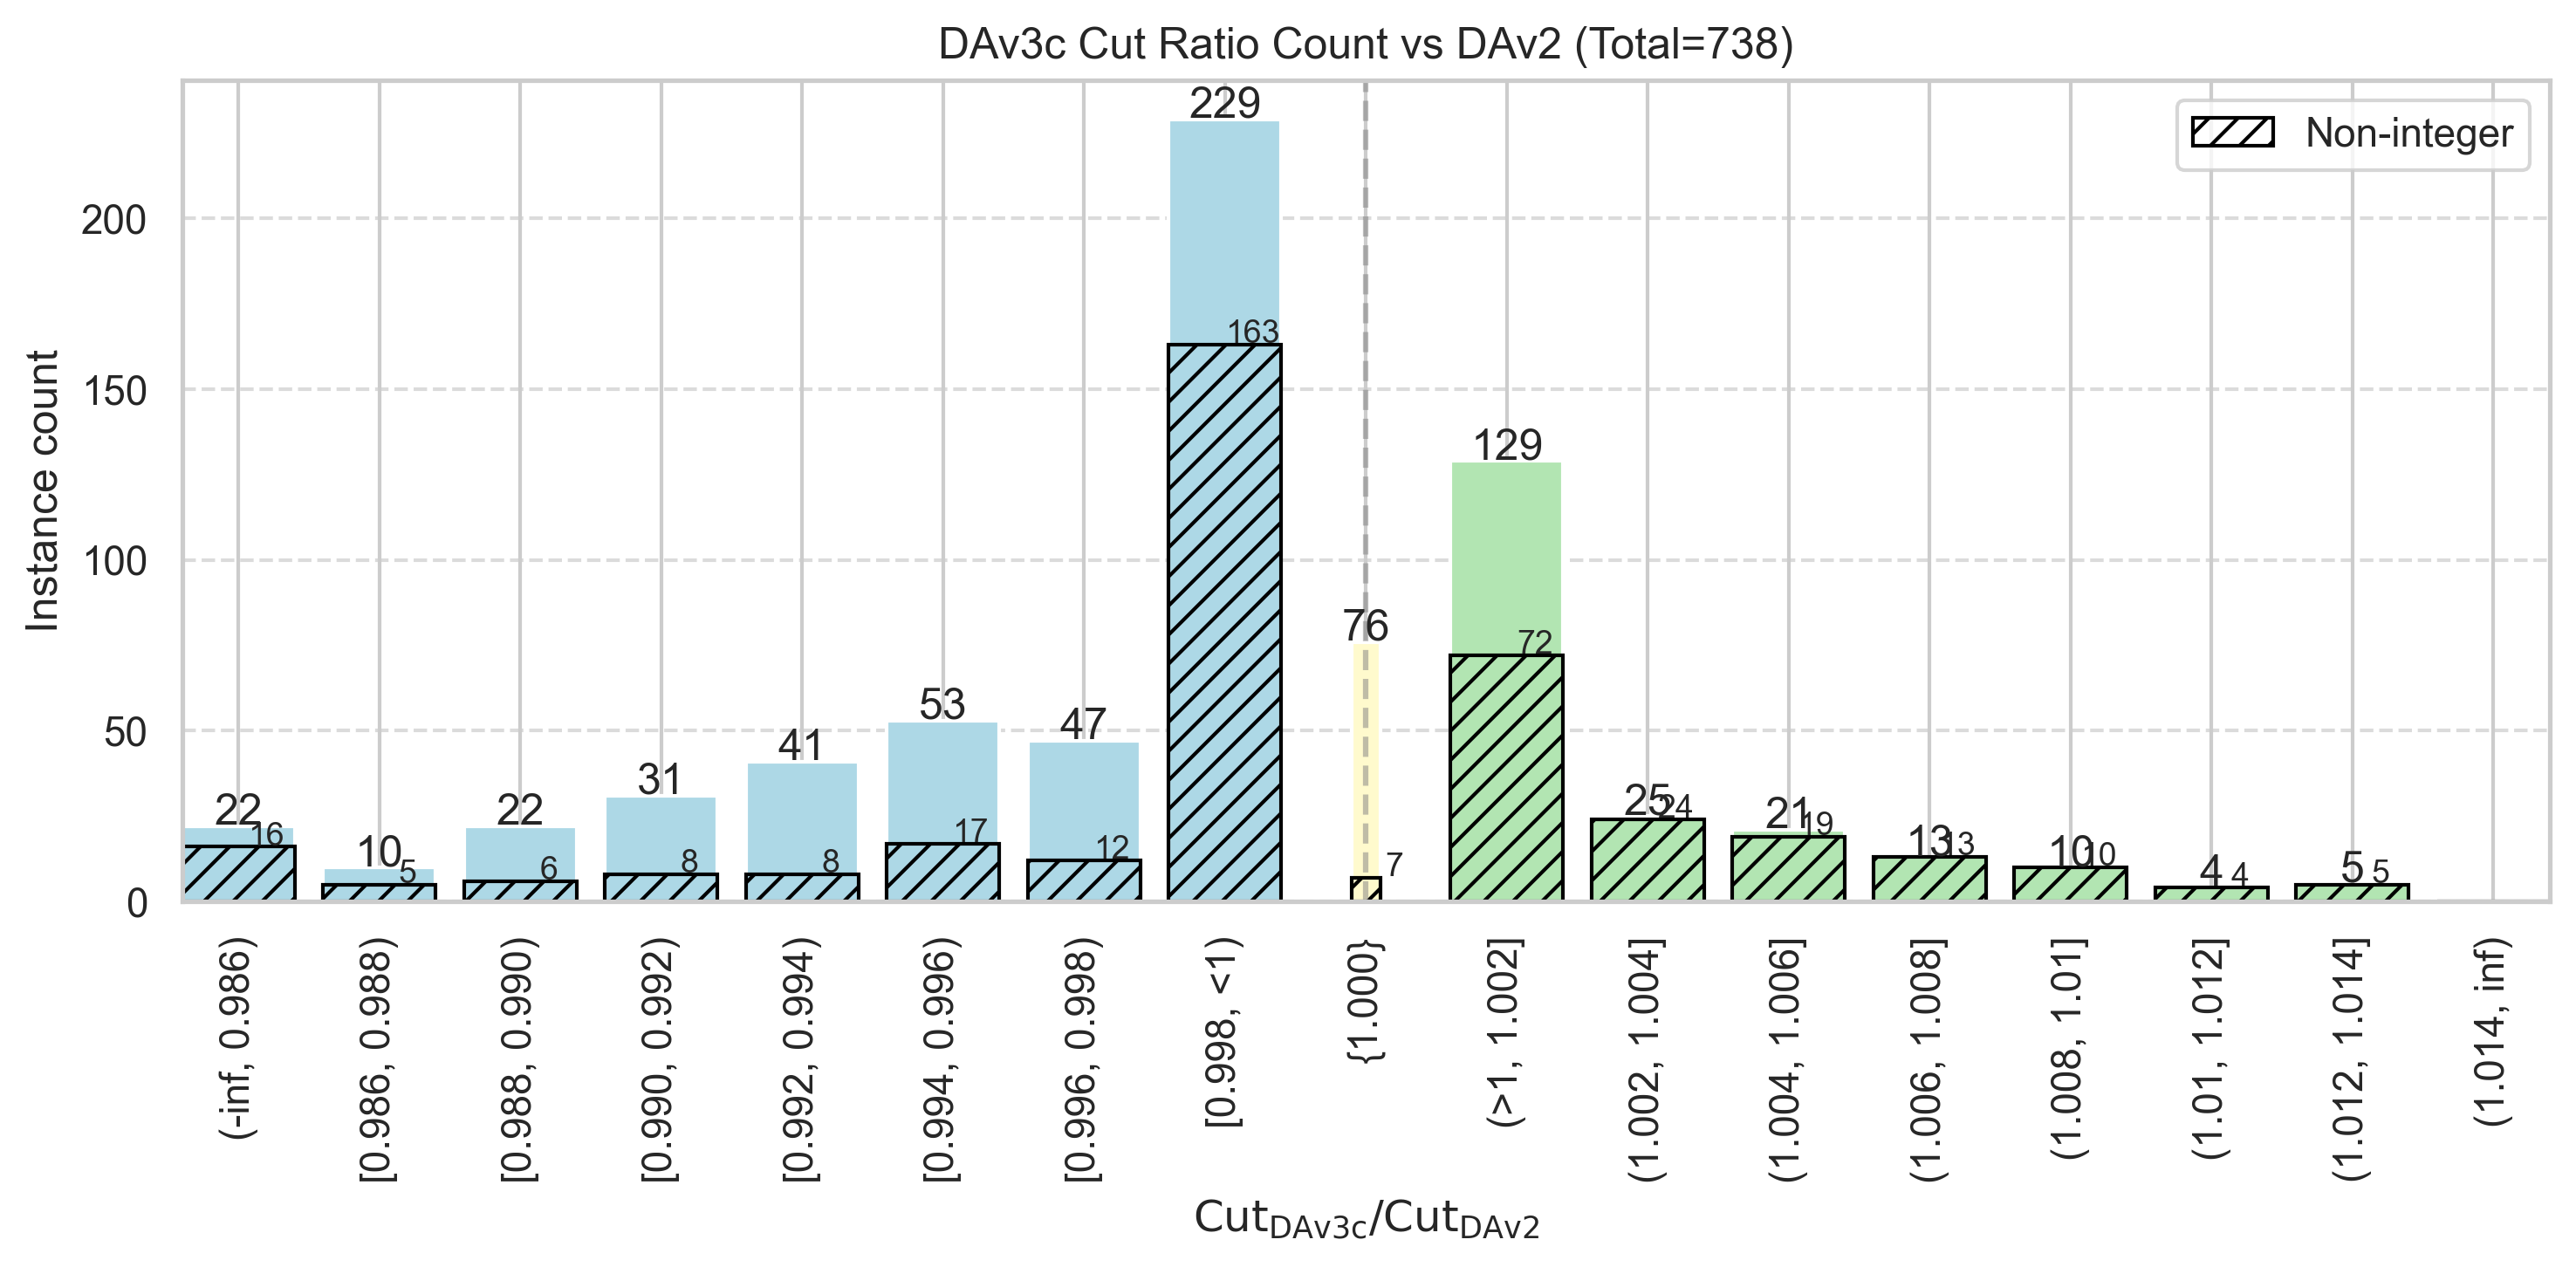

In [25]:
# Purpose: Compute DAv3c/DAv2 cut-ratio counts and validation diagnostics.
ratio_result_dav2 = utils.compute_cut_ratio_counts(
    df=df_dav2,
    solver_col="DAv3c",
    baseline_col="DAv2",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav2["tie_count"])
print("Ratio == 1.0:", ratio_result_dav2["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav2,
    solver_label="DAv3c",
    baseline_label="DAv2",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv2_Cut_Ratio_Count.pdf",
)

In [26]:
# Purpose: Run the overall paired Wilcoxon test for DAv3c versus DAv2.
utils.run_wilcoxon(df_dav2, "DAv3c", "DAv2", "DAv3c vs DAv2")


=== DAv3c vs DAv2 ===
Total paired samples: 738
Numerical ties: 76
Samples used: 662
Wilcoxon statistic: 79456.0
p-value: 7.7785e-10
Rank-biserial correlation: -0.2759
Median difference: -100
Result: Statistically significant (unadjusted)


{'n_total': 738,
 'n_nonzero': 662,
 'n_ties': 76,
 'stat': np.float64(79456.0),
 'p_raw': np.float64(7.778464349562325e-10),
 'r_rb': np.float64(-0.2758722824477223)}

In [27]:
# Purpose: Report category-level Holm-adjusted paired tests.
res_dav2 = utils.wilcoxon_by_category(df_dav2, "DAv3c", "DAv2")
utils.print_wilcoxon_Pairwise_results(res_dav2 , "DAv3c vs DAv2 (Category-wise)")


=== DAv3c vs DAv2 (Category-wise) ===
large_balanced       | n=113 | ties=  6 | p_raw=8.4852e-02 | p_holm=1.6970e-01 | r_rb=-0.187 | Not significant
large_dense          | n= 37 | ties=  4 | p_raw=6.8601e-03 | p_holm=2.7441e-02 | r_rb=-0.502 | Significant
large_sparse         | n=161 | ties= 10 | p_raw=4.5209e-01 | p_holm=4.5209e-01 | r_rb=+0.068 | Not significant
medium_balanced      | n= 68 | ties= 10 | p_raw=4.5707e-02 | p_holm=1.3712e-01 | r_rb=-0.279 | Not significant
medium_dense         | n= 44 | ties=  6 | p_raw=6.4758e-05 | p_holm=3.2379e-04 | r_rb=-0.661 | Significant
medium_sparse        | n=239 | ties= 40 | p_raw=1.4428e-11 | p_holm=8.6565e-11 | r_rb=-0.504 | Significant


## 8. Integer versus non-integer edge-weight representations

This section studies whether pairwise outcomes vary by edge-weight type (`int_only`). **Integer** means the source flag is true; **float/non-integer** is the complementary label used in the original analysis. This grouping describes representation and should not be interpreted as a controlled causal manipulation of rounding or scaling.

### 8.1 Combined solver-versus-heuristic plot

The combined chart starts from Medium and Large instances, then independently drops missing scores for each solver. Consequently, a single visual panel is **not itself proof** that all solver rows use identical instance sets. A later assertion explicitly verifies common IDs for the matched statistical analysis.

In [28]:
# Purpose: Define a function to group Medium/Large cases by category and weight type.
import numpy as np
import pandas as pd

def prepare_combined_wtl(df_baseline):

    df = df_baseline[
        df_baseline["size_cat"].isin(["medium", "large"])
    ].copy()

    df["category"] = (
        df["size_cat"].astype(str)
        + "_"
        + df["density_cat"].astype(str)
    )

    df["weight_type"] = np.where(
        df["int_only"] == True,
        "integer",
        "float"
    )

    results = []

    for solver in ["DAv2", "DAv3", "DAv3c"]:

        temp = df[
            [
                "name",
                "category",
                "weight_type",
                solver,
                "heuristic"
            ]
        ].dropna().copy()

        temp["result"] = temp.apply(
            lambda row: utils.compare_scores(
                row[solver],
                row["heuristic"]
            ),
            axis=1
        )

        temp["solver"] = solver
        results.append(
            temp[["category", "weight_type", "solver", "result"]]
        )

    df_combined = pd.concat(results, ignore_index=True)

    pivot_df = (
        df_combined
        .groupby(["category", "weight_type", "solver", "result"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["loss", "tie", "win"], fill_value=0)
        .reset_index()
    )

    return pivot_df

In [29]:
# Purpose: Prepare the counts used in the combined three-solver panel.
pivot_combined = prepare_combined_wtl(df_baseline)

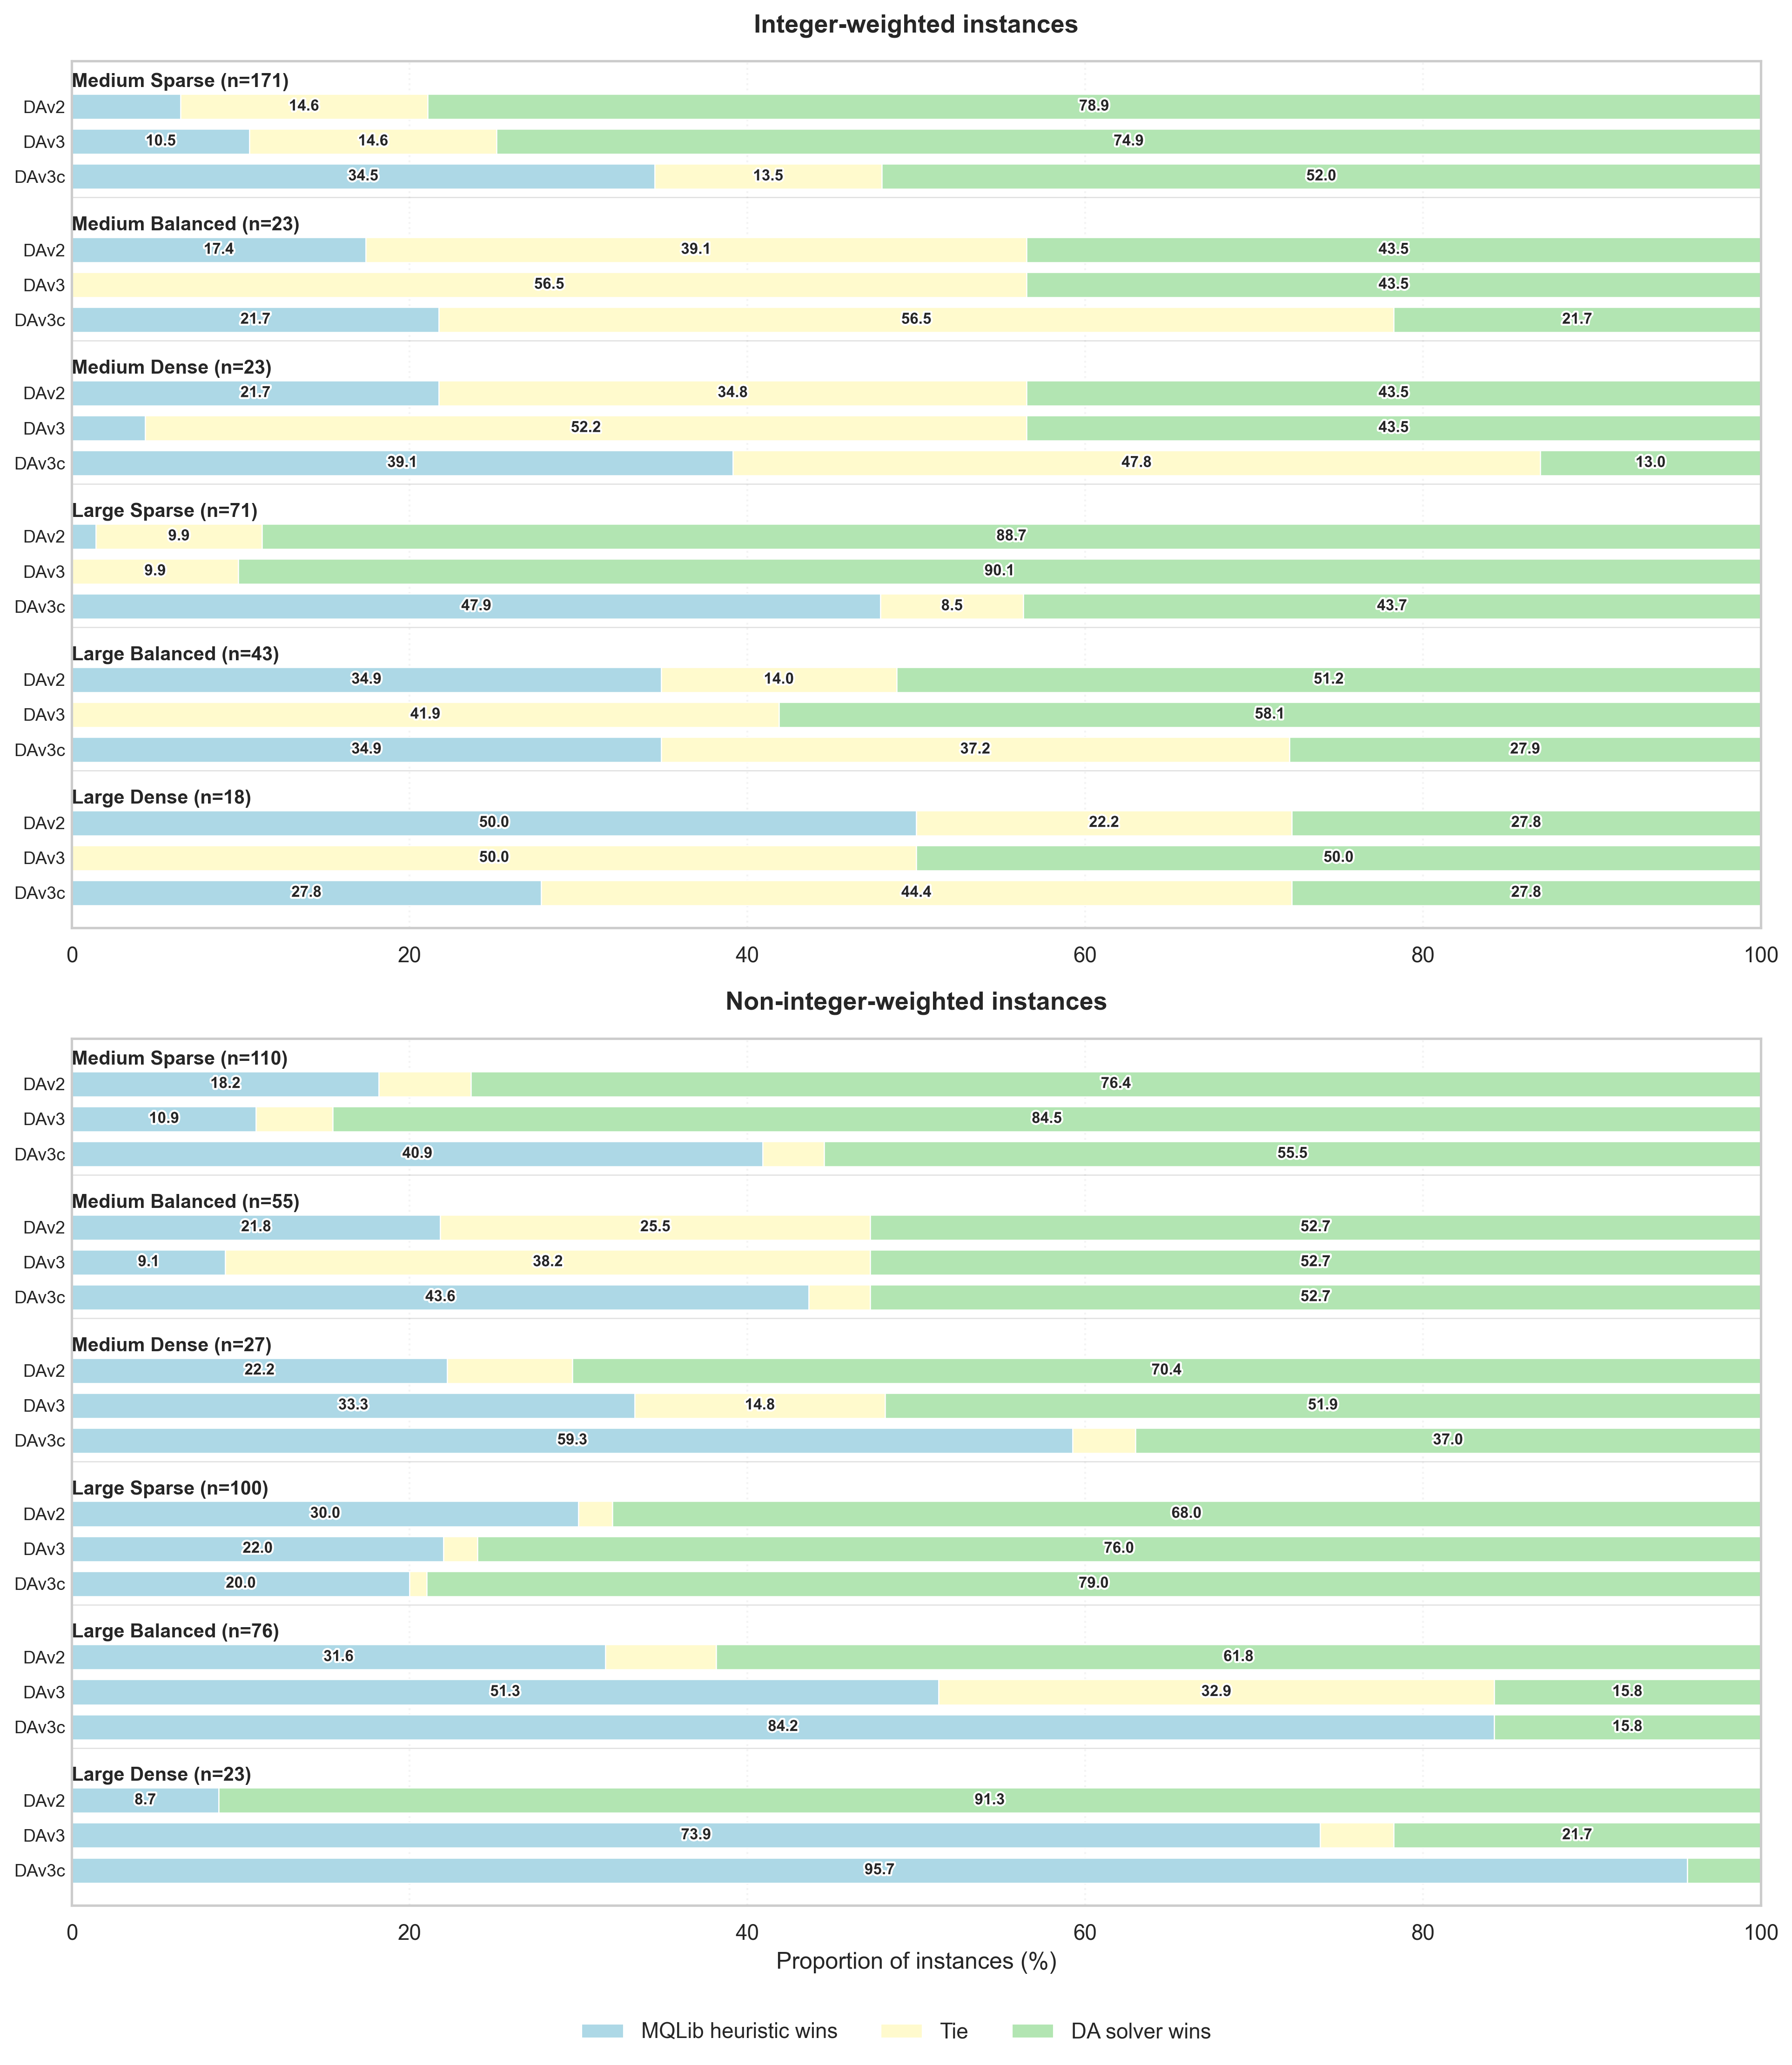

In [30]:
# Purpose: Render the combined solver-versus-heuristic plot by weight representation.
fig, axes = plotting.plot_combined_wtl_by_weight_type(
    pivot_df=pivot_combined,
    save_name="DA_vs_MQLib_integer_float_size_density.pdf",
    figsize=(13, 15)
)

## 8.2 Individual solver-versus-heuristic outcomes by weight type

For DAv2 and DAv3, separate tables and plots compare each system with the MQLib heuristic baseline. The DAv3c weight-type plot follows using the previously prepared heuristic comparison. The later combined figure excludes XLarge for DAv3/DAv3c to align eligible size categories with DAv2.

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv2 vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

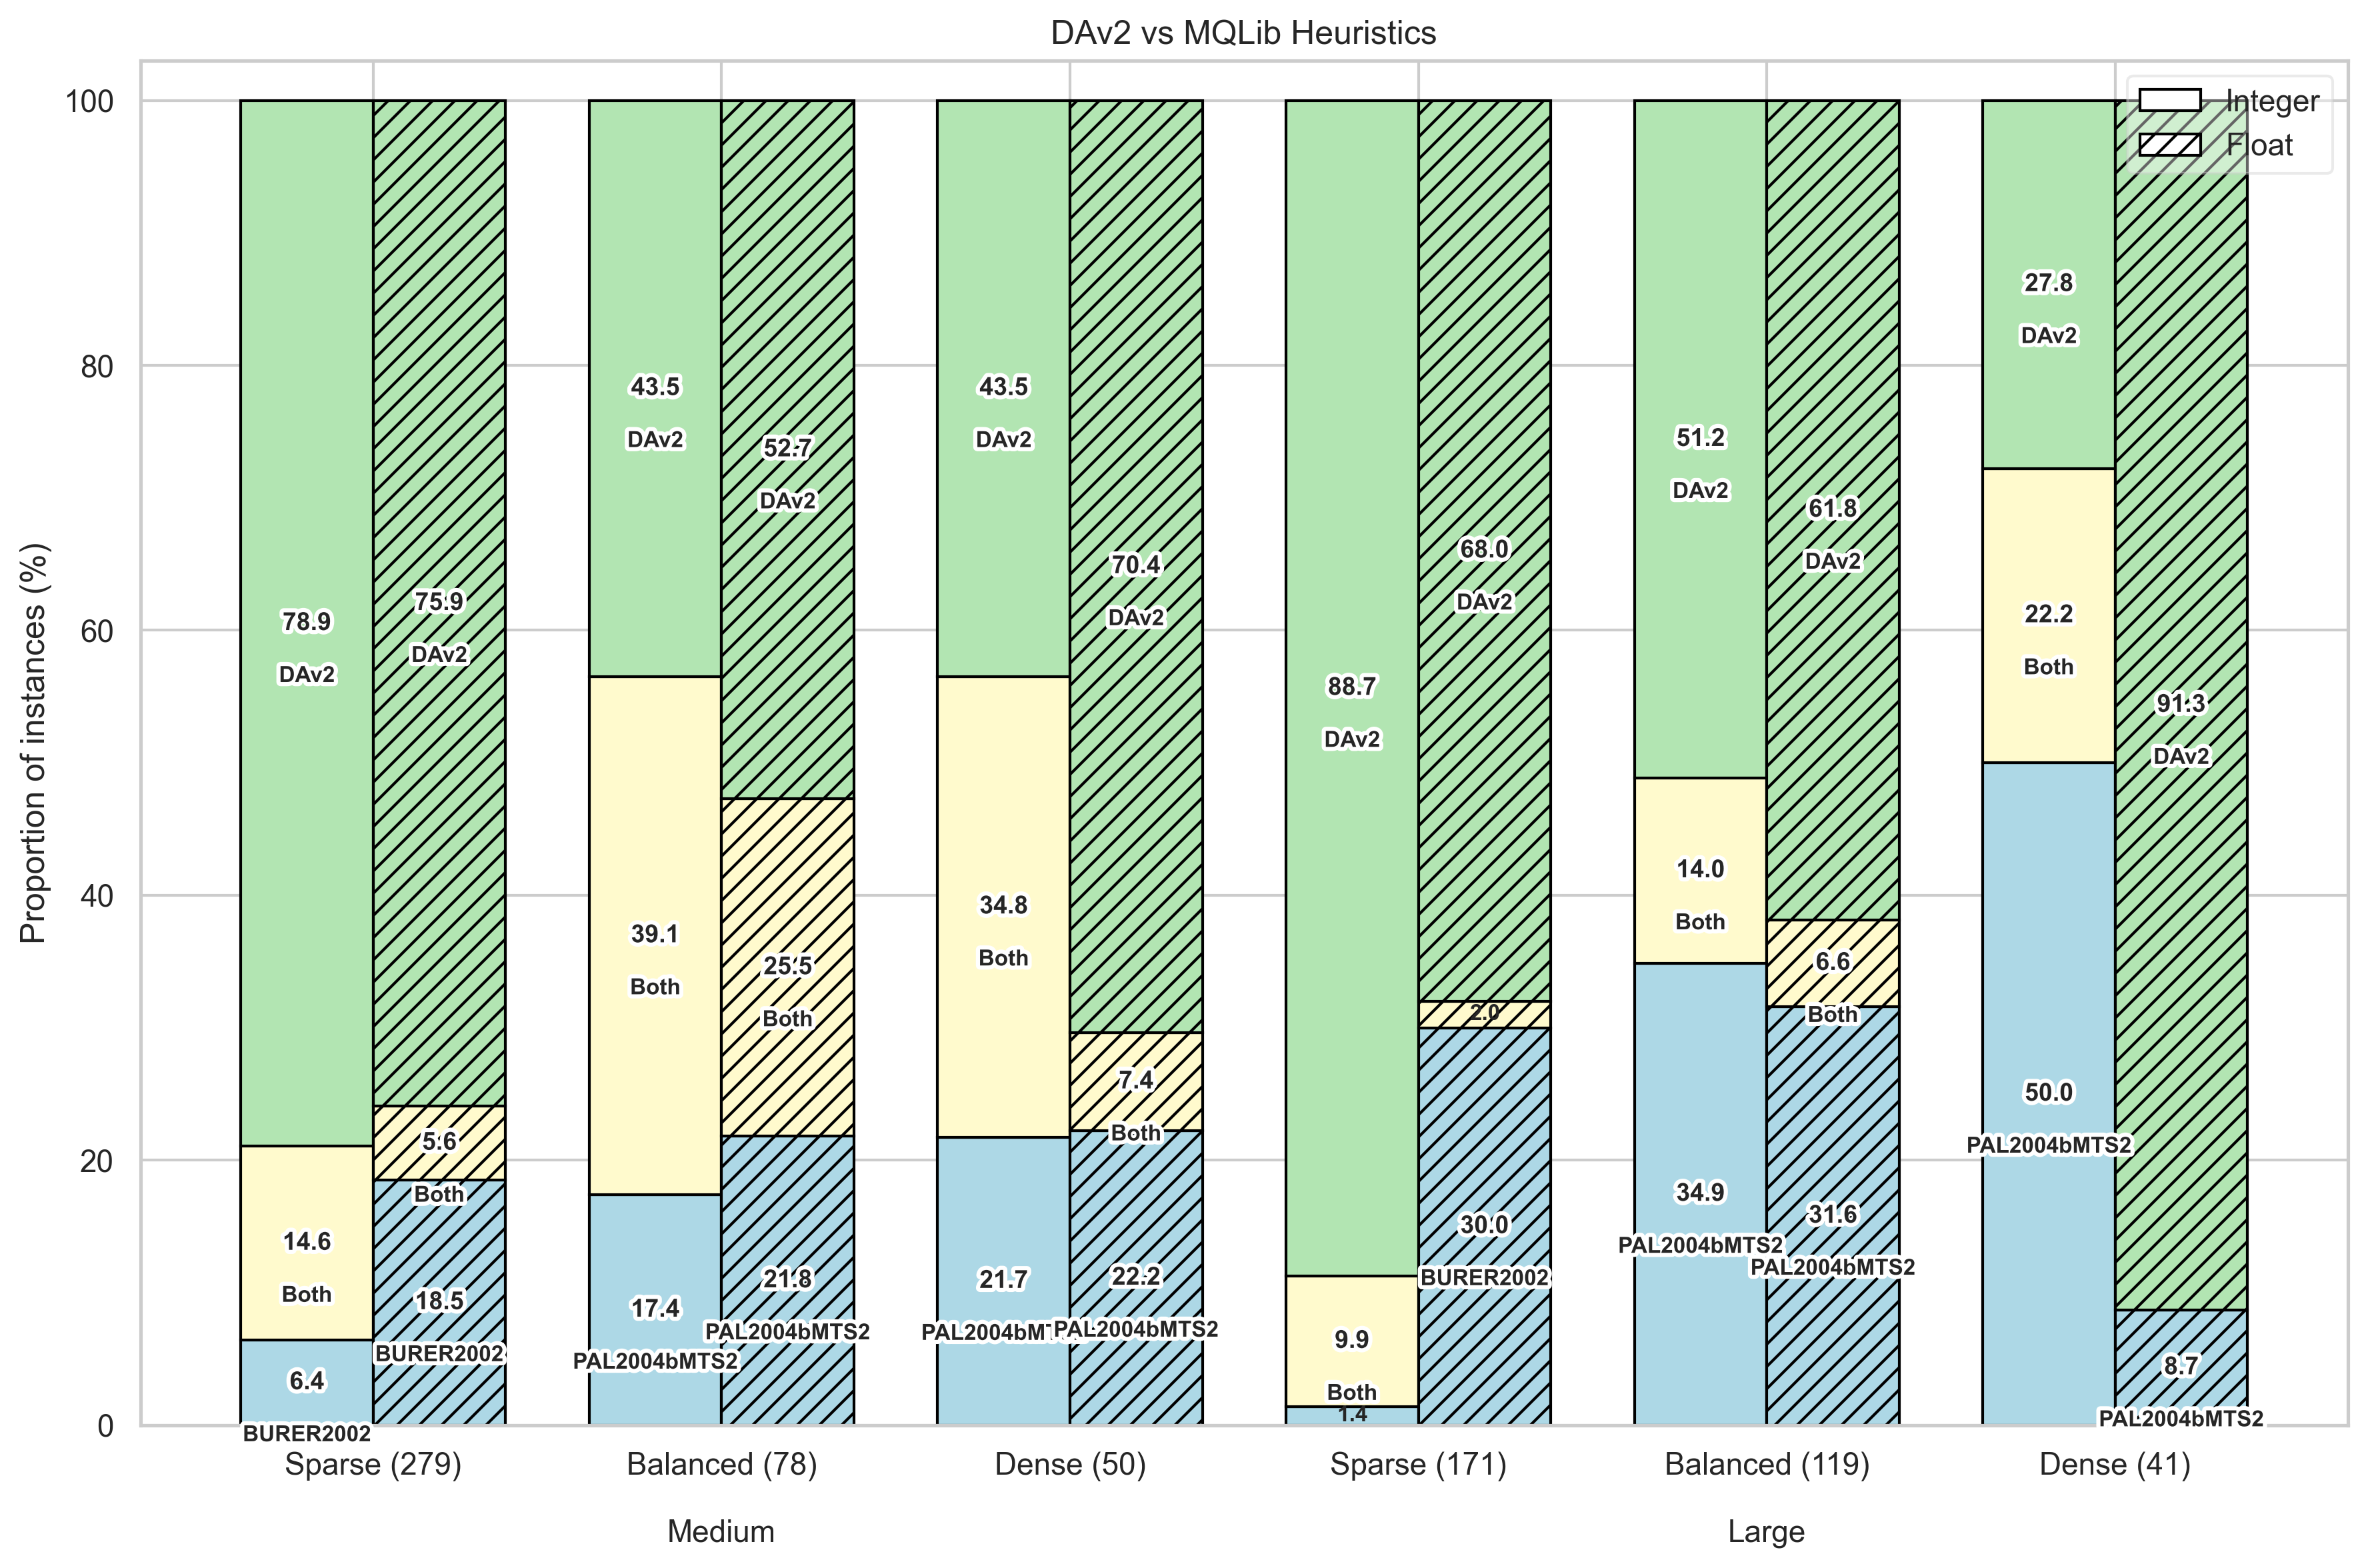

In [31]:
# Purpose: Produce the DAv2-versus-heuristic weight-type plot.
df_dav2_heu = df_dav2.copy()
df_dav2_heu ['result'] = df_dav2_heu .apply(lambda row: utils.compare_scores(row["DAv2"], row["heuristic"]), axis=1)
pivot_table_heu_v2, summary_heu_v2 = utils.conparison_summary(df_dav2_heu)

plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu_v2,
    title="DAv2 vs MQLib Heuristics",
    save_name="dav2_vs heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv2",
    use_category_loss_labels=True,
)

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3 vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

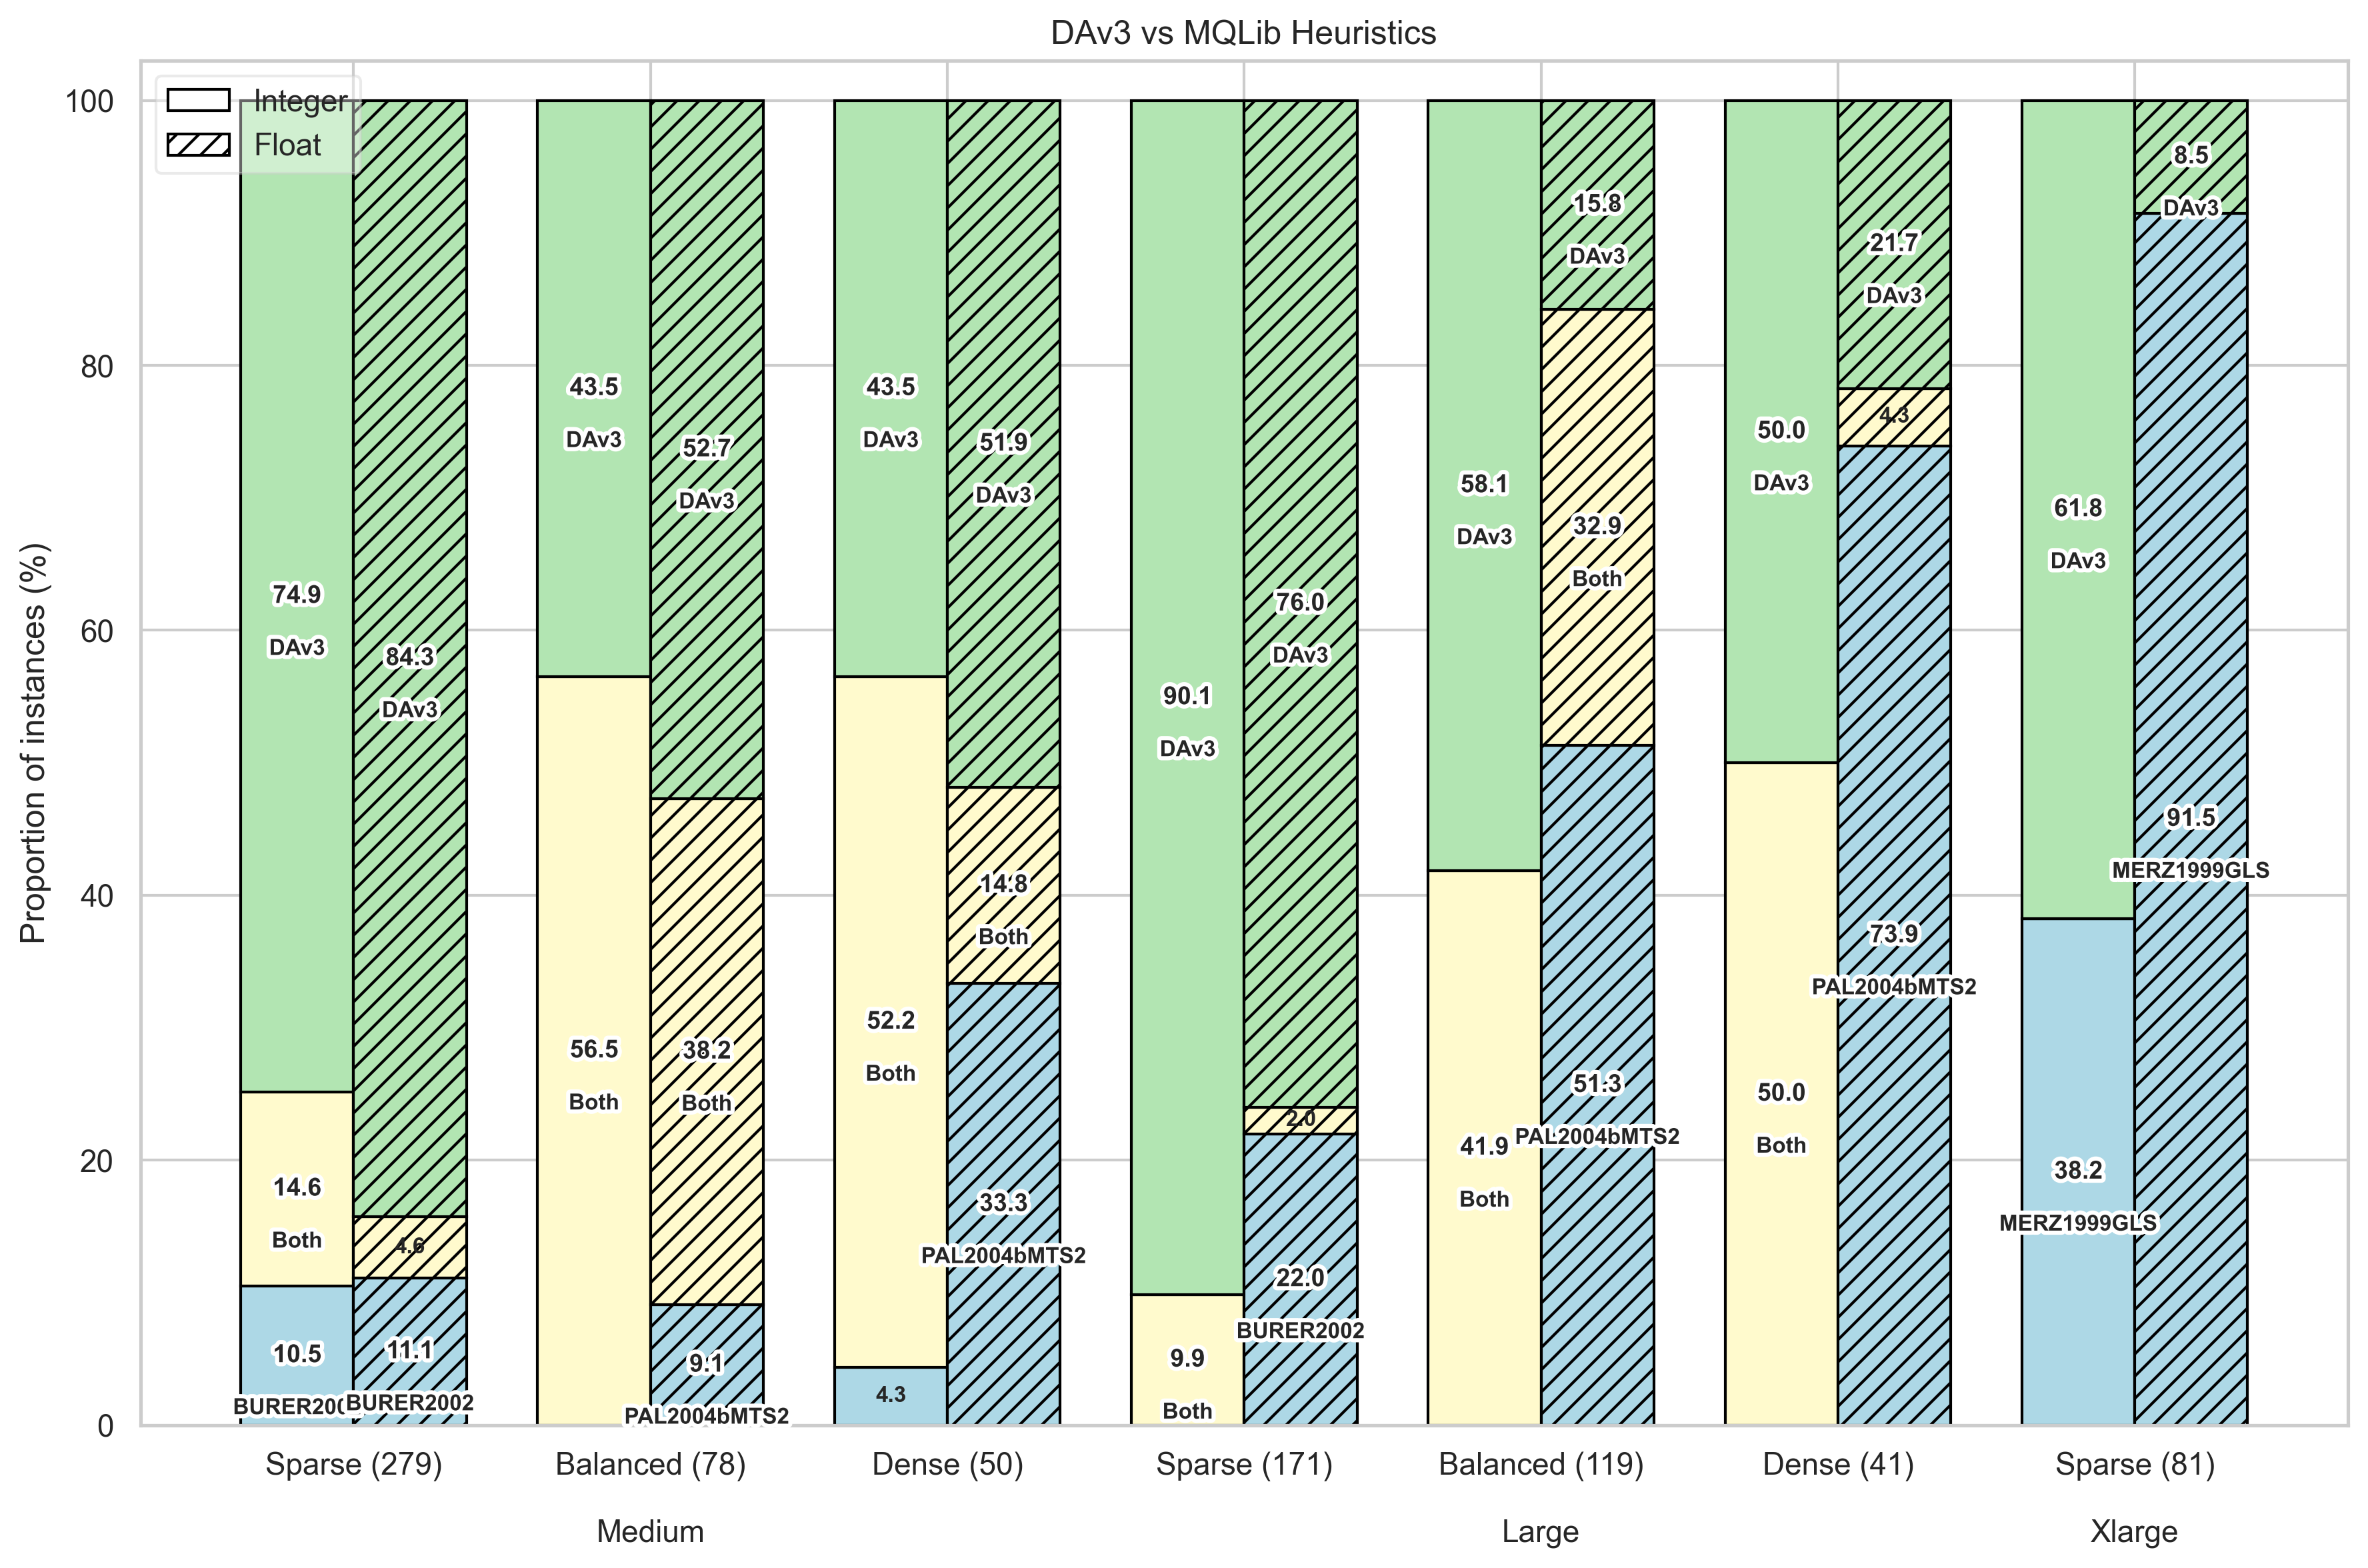

In [32]:
# Purpose: Produce the DAv3-versus-heuristic weight-type plot.
df_dav3_heu = df_dav3.copy()
df_dav3_heu ['result'] = df_dav3_heu .apply(lambda row: utils.compare_scores(row["DAv3"], row["heuristic"]), axis=1)
pivot_table_heu_v3, summary_heu_v3 = utils.conparison_summary(df_dav3_heu)


plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu_v3,
    title="DAv3 vs MQLib Heuristics",
    save_name="dav3_vs_heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv3",
    use_category_loss_labels=True,
)

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

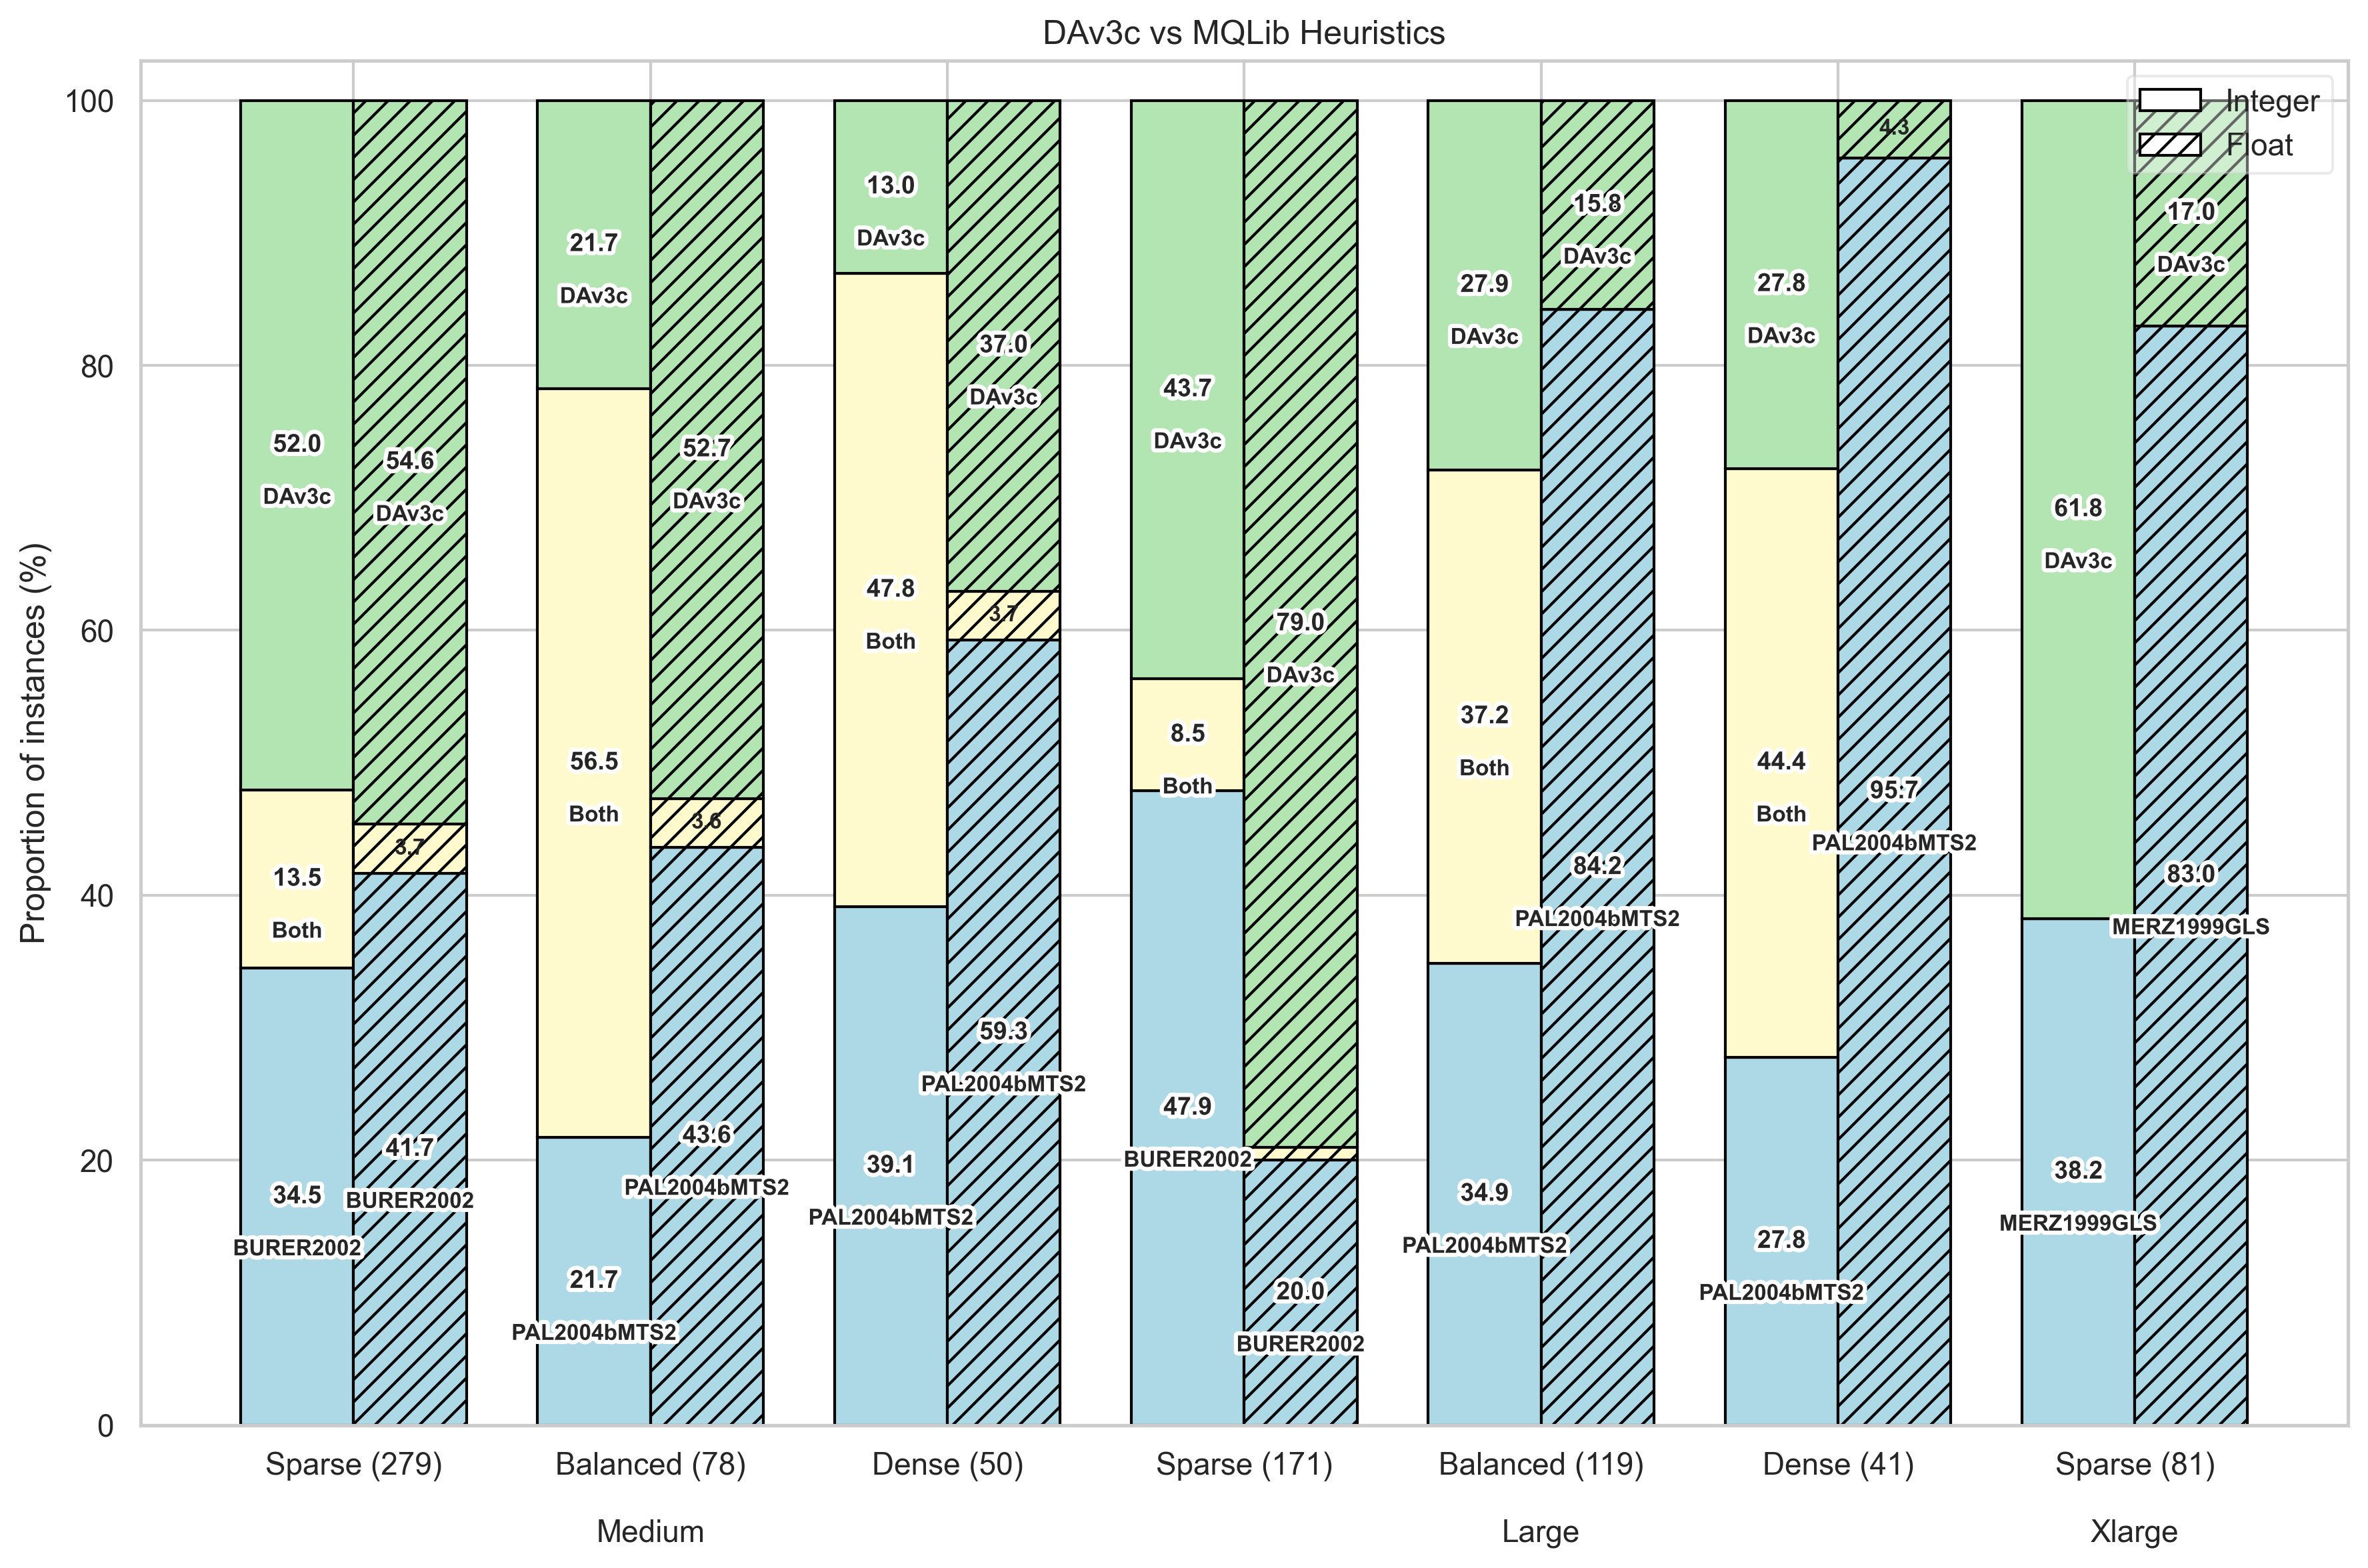

In [33]:
# Purpose: Produce the DAv3c-versus-heuristic weight-type plot.
plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu,
    title="DAv3c vs MQLib Heuristics",
    save_name="dav3c_vs_heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv3c",
    use_category_loss_labels=True,
)

## 8.3 Combined solver summary on non-XLarge cases

The combined utility summarizes each solver's wins, ties, and losses by weight type. This chart is descriptive. Verify counts and source instance IDs before interpreting solver differences as arising from edge-weight representation alone.

result solver weight_type  loss  tie  win
0        DAv2       float    94   29  266
1        DAv2     integer    45   59  245
2        DAv3       float   104   58  227
3        DAv3     integer    19   84  246
4       DAv3c       float   191    8  190
5       DAv3c     integer   127   77  145


(<Figure size 3000x1800 with 1 Axes>,
 <Axes: title={'center': 'DA Solvers vs MQLib Heuristics by Weight Type'}, ylabel='Proportion of instances (%)'>)

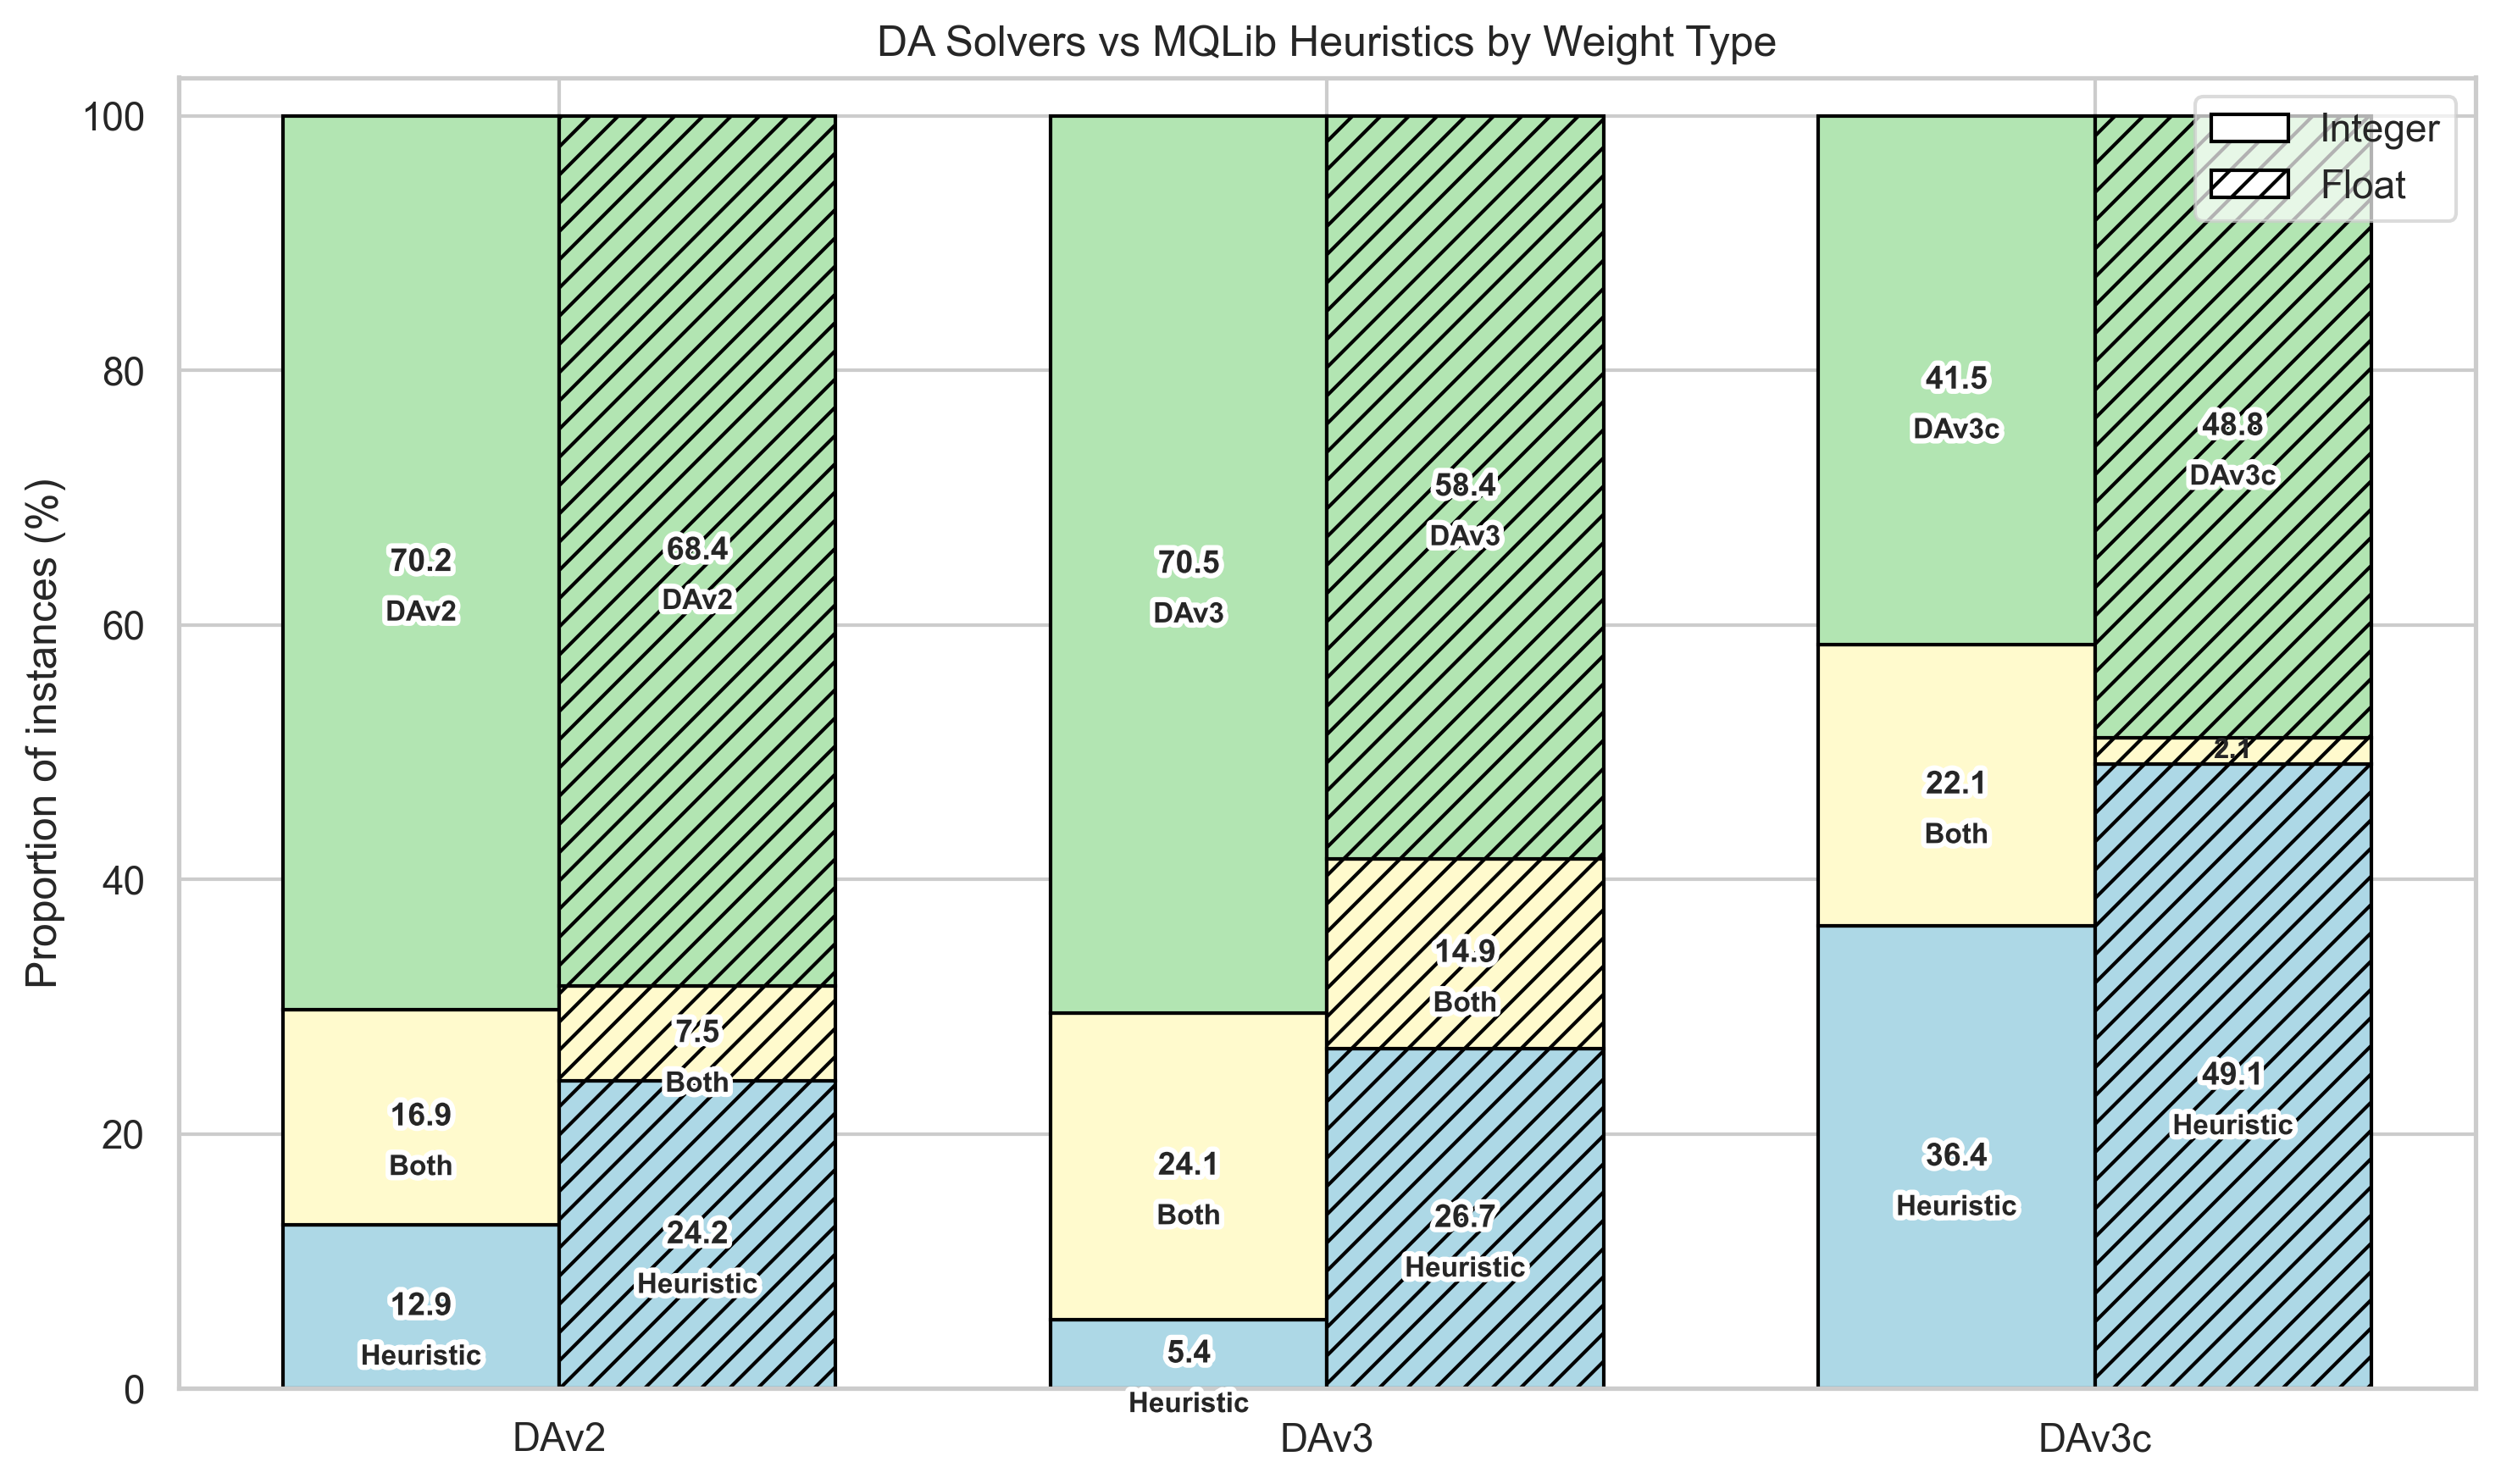

In [34]:
# Purpose: Aggregate solver-versus-heuristic outcomes excluding XLarge.
df_dav3_ = df_dav3_heu[~df_dav3_heu['size_cat'].isin(['xlarge'])]
df_dav3c_ = df_heu[~df_heu['size_cat'].isin(['xlarge'])]
summary = utils.tie_loss_win_counts(
    df_dav2_heu,
    df_dav3_,
    df_dav3c_
)
print(summary)
plotting.plot_combined_solver_weighttype_wtl(
    summary=summary,
    title="DA Solvers vs MQLib Heuristics by Weight Type",
    save_name="combined_solver_weighttype_wtl.pdf",
    loss_label="Heuristic",
    win_label="Solver",
)

In [35]:
# Purpose: Display the number of non-null `int_only` flags in the DAv3 subset.
df_dav3_['int_only'].count()

np.int64(738)

## 10. Matched 738-instance statistical analysis by weight type

### 10.1 Construct per-solver panels

The original analysis prepares DAv2, DAv3, and DAv3c panels and applies paired Wilcoxon tests against the MQLib heuristic separately for integer and non-integer graphs. **Important:** `df_dav2` and `df_dav3` are reassigned here for this specific analysis. The stated 738-instance common sample is validated by the next cell's instance-ID assertion; the row count should also be checked when the notebook is rerun.

In [36]:
# Purpose: Assemble weight-type Wilcoxon results on the intended common 738-instance subset.
import pandas as pd
import numpy as np

# Use the same 738 common instances as the weight-type plot
df_dav2 = df_dav2_heu.copy()

df_dav3 = df_dav3_heu[
    ~df_dav3_heu["size_cat"].isin(["xlarge"])
].copy()

df_dav3c = df_heu[
    ~df_heu["size_cat"].isin(["xlarge"])
].copy()

# Create integer / non-integer categories
for df in [df_dav2, df_dav3, df_dav3c]:
    df["weight_type"] = np.where(
        df["int_only"].astype(bool),
        "integer",
        "float"
    )

# Run paired Wilcoxon tests for each solver
results = []

for solver_name, df in [
    ("DAv2", df_dav2),
    ("DAv3", df_dav3),
    ("DAv3c", df_dav3c),
]:
    res = utils.wilcoxon_by_category(
        df,
        col_a=solver_name,
        col_b="heuristic",
        category_col="weight_type",
        eps=1e-9
    )

    res.insert(0, "solver", solver_name)
    results.append(res)

df_significance = pd.concat(results, ignore_index=True)

display(
    df_significance[
        [
            "solver",
            "category",
            "n_total",
            "n_nonzero",
            "n_ties",
            "p_raw",
            "p_holm",
            "r_rb",
            "status"
        ]
    ]
)

,solver,category,n_total,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,DAv2,float,389,360,29,1.204062e-08,1.204062e-08,0.346599,Significant
1,DAv2,integer,349,290,59,4.271613e-20,8.543225e-20,0.621993,Significant
2,DAv3,float,389,331,58,2.489975e-13,2.489975e-13,0.464201,Significant
3,DAv3,integer,349,265,84,8.218066e-25,1.643613e-24,0.728869,Significant
4,DAv3c,float,389,381,8,6.829402e-02,1.365880e-01,0.107776,Not significant
5,DAv3c,integer,349,272,77,9.478094e-01,9.478094e-01,0.004579,Not significant


## 10.2 Verify matched instance membership

The asserted equality of `name` sets confirms that all three panels represent the same **unique instance IDs**, provided those IDs occur only once per frame. It does not independently verify score equivalence or exclude duplicate rows; if there are duplicates, inspect them before making matched-population claims.

In [37]:
# Purpose: Assert common instance ID membership across DAv2, DAv3, and DAv3c.
ids_dav2 = set(df_dav2["name"])
ids_dav3 = set(df_dav3["name"])
ids_dav3c = set(df_dav3c["name"])

assert ids_dav2 == ids_dav3 == ids_dav3c
assert len(ids_dav2) == 738

print("All three solvers use the same 738 instances.")

All three solvers use the same 738 instances.


## 10.3 Holm adjustment across all six weight-type tests

The preceding per-solver helper may adjust p-values within smaller families. Here the original code performs one additional **Holm correction over the complete family of six tests** (three solvers × two weight types). Use `p_holm_all6` for claims referring to the joint six-test family; do not substitute the earlier `p_holm` without specifying its correction family.

In [38]:
# Purpose: Perform a single six-comparison Holm correction for the weight-type tests.
from statsmodels.stats.multitest import multipletests

reject, p_adjusted, _, _ = multipletests(
    df_significance["p_raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)

df_significance["p_holm_all6"] = p_adjusted
df_significance["significant_all6"] = reject

display(df_significance[
    ["solver", "category", "p_raw", "p_holm_all6", "r_rb", "significant_all6"]
])

,solver,category,p_raw,p_holm_all6,r_rb,significant_all6
0,DAv2,float,1.204062e-08,3.612185e-08,0.346599,True
1,DAv2,integer,4.271613e-20,2.135806e-19,0.621993,True
2,DAv3,float,2.489975e-13,9.959901e-13,0.464201,True
3,DAv3,integer,8.218066e-25,4.930839e-24,0.728869,True
4,DAv3c,float,6.829402e-02,1.365880e-01,0.107776,False
5,DAv3c,integer,9.478094e-01,9.478094e-01,0.004579,False


In [ ]:
# Purpose: Check that weight-type group counts agree across solver panels.
for name, df in [
    ("DAv2", df_dav2),
    ("DAv3", df_dav3),
    ("DAv3c", df_dav3c),
]:
    print(f"\n{name}")
    print(df["weight_type"].value_counts())

## 11. XLarge and additional comparison diagnostics

The XLarge summary is restricted to DAv3 and DAv3c because DAv2 does not cover that size category. The comparison registry and weight-type labels below are retained from the source notebook for inspection or downstream reuse; they do not themselves produce another statistical result.

In [ ]:
# Purpose: Summarize DAv3 and DAv3c outcomes on XLarge graphs only.
summary_xlarge = utils.tie_loss_win_counts(
    df_dav3 = df_dav3_heu[df_dav3_heu['size_cat'].isin(['xlarge'])],
    df_dav3c= df_heu[df_heu['size_cat'].isin(['xlarge'])]
)
print(summary_xlarge)

In [ ]:
# Purpose: Register each solver-versus-heuristic comparison for diagnostics.
comparisons = [
    {
        "df": df_dav2_heu,
        "solver_col": "DAv2",
        "baseline_col": "heuristic",
        "label": "DAv2 vs Heuristic",
    },
    {
        "df": df_dav3_heu,
        "solver_col": "DAv3",
        "baseline_col": "heuristic",
        "label": "DAv3 vs Heuristic",
    },
    {
        "df": df_heu,
        "solver_col": "DAv3c",
        "baseline_col": "heuristic",
        "label": "DAv3c vs Heuristic",
    },
]

In [ ]:
# Purpose: Inspect which size categories are represented in the DAv3 heuristic panel.
df_dav3_heu['size_cat'].unique()

In [ ]:
# Purpose: Attach explicit integer/float labels to comparison datasets.
for comp in comparisons:
    comp["df"]["weight_type"] = np.where(
        comp["df"]["int_only"],
        "integer",
        "float"
    )

## 12. Supplemental small-instance comparison

This section uses `utils.filter_small_instances` rather than the main-instance selection. It is presented separately because its eligibility rules and size distribution differ from the Medium/Large/XLarge analyses. The plot reports DAv3c relative to the MQLib heuristic on that smaller-instance population.

In [ ]:
# Purpose: Select and report small-instance population from the separate filter.
df_small = utils.filter_small_instances(df_baseline,'heuristic')
df_small["category"] = (df_small["size_cat"] + "_" + df_small["density_cat"])
print(f'Total Number of Instances: {len(df_small)}')
print('............')
print(f"Size Category Distribution: {df_small['size_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_small['density_cat'].value_counts()}")
print('............')
print(f"Density Category Distribution: {df_small['category'].value_counts()}")

In [ ]:
# Purpose: Assign DAv3c-versus-heuristic outcomes for small instances.
df_small['result'] = df_small.apply(lambda row: utils.compare_scores(row["DAv3c"], row["heuristic"]), axis=1)

In [ ]:
# Purpose: Aggregate the small-instance outcome table.
pivot_table_small, summary_small = utils.conparison_summary(df_small)
print(pivot_table_small)

In [ ]:
# Purpose: Plot small-instance win/tie/loss by category.
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_small,
    pivot_table=pivot_table_small,
    title="DAv3c vs MQLib Heuristics per Category",
    win_label="DAv3c",
    loss_label="Heuristic",
    use_category_loss_labels=True,
    save_name="dav3c_vs_heuristics_small_category.pdf",
)

## 13. Interpretation and reproducibility checklist

The above outputs should be read alongside the conference paper's description of selection criteria and baseline construction. When regenerating figures and statistical tables, check that:

- **Graph selection:** sample sizes, category distribution, and the use or exclusion of `xlarge` match the figure or claim being reproduced.
- **Pair orientation:** win/loss direction agrees with the first solver in the comparison name; pairwise counts are **not automatically cross-comparable** when filtering differs.
- **Ties and cut ratios:** comparisons use the repository's score-comparison and ratio utilities. Near-unity ratios indicate similar cut values but do not imply exact equality.
- **Weight types:** the integer and float/non-integer labels follow the dataset's `int_only` flag; observed differences can be confounded with graph structure or instance composition.
- **Statistical reporting:** cite the test definition, absolute numerical-tie tolerance, nonzero pair count, effect size, and the precise Holm correction family (per-category or all-six, as applicable).
- **Reproducibility:** the source input is `baseline_enriched.csv`, with logic delegated to `src/maxcut/config.py`, `utils.py`, and `plotting.py`. Run from the repository's notebook directory and regenerate the saved PDFs.

**Scope:** This notebook establishes observed comparative performance on the evaluated instances; it does not establish proven Max-Cut optimality or causally isolate solver implementation, hardware, or coefficient-representation effects.
